## Problema - Conectando una protoboard con la menor cantidad de cable

**Equipo Extasys Code:** Juan Pablo León, Santiago Lugo y Alejandro Peña

Un equipo de electrónica ubicó siete componentes en una protoboard de 10 filas (A a J) y 30 columnas, y necesita conectarlos todos usando la menor cantidad posible de cable. Cada componente es un vértice, cada cable posible es una arista y su longitud es el peso. El cableado óptimo es un Árbol de Expansión Mínima (MST), que se construye con el algoritmo de Kruskal implementado a mano, sin librerías de grafos.

In [1]:
# @title Ingrese datos
equipo = "Extasys Code" # @param {"type":"string"}
nombre_estudiante = "Santiago Lugo Gómez" # @param {"type":"string"}
carnet = 1000113097 # @param {"type":"integer"}

## 1) Descripción del problema **[1 pts]**

Se deben conectar siete componentes ubicados en una protoboard con la menor longitud total de cable. No se evalúa el funcionamiento eléctrico: la protoboard solo da la posición de cada componente.

### Modelo matemático

**Protoboard.** Es la cuadrícula $\mathcal{P} = \{A, \dots, J\} \times \{1, \dots, 30\}$, con 300 perforaciones. Cada posición se convierte en coordenadas $(c, f)$, donde $c$ es la columna y $f$ el número de la fila: $f(A) = 1, f(B) = 2, \dots, f(J) = 10$. Por ejemplo, A3 se convierte en $(3, 1)$.

**Grafo.** Los componentes forman el conjunto de vértices $V = \{F, L, S, P, B, R, M\}$, con $n = |V| = 7$. Cualquier pareja se puede unir con un cable, así que el grafo es completo y no dirigido:

$$G = (V, E, w), \qquad E = \{\{u, v\} : u, v \in V,\ u \neq v\}, \qquad |E| = \binom{n}{2} = \frac{n(n-1)}{2} = 21$$

**Peso.** La longitud del cable entre $u = (c_u, f_u)$ y $v = (c_v, f_v)$ es la distancia Manhattan:

$$w(u, v) = |c_u - c_v| + |f_u - f_v|$$

Es el largo de un cable que avanza por columnas y filas, sin diagonales. Cumple $w(u, v) \ge 0$, $w(u, v) = w(v, u)$, $w(u, v) = 0$ solo si los dos componentes están en la misma perforación, y la desigualdad triangular. En esta protoboard el máximo es $w(A1, J30) = 29 + 9 = 38$.

**Objetivo.** Un árbol de expansión es un conjunto $T \subseteq E$ de $n - 1$ aristas que conecta todos los vértices; como es conexo y tiene $n - 1$ aristas, no tiene ciclos. Se busca el de menor peso total:

$$T^{*} = \arg\min_{T \in \mathcal{T}(G)} W(T), \qquad W(T) = \sum_{\{u, v\} \in T} w(u, v)$$

Todos los árboles tienen 6 cables, así que lo que se minimiza es la suma de las longitudes, no la cantidad de cables. Por la fórmula de Cayley, el grafo completo tiene $n^{n-2} = 7^5 = 16\,807$ árboles de expansión, y ese número crece demasiado rápido para probarlos todos (con 30 componentes serían $30^{28} \approx 2{,}3 \times 10^{41}$). Kruskal encuentra $T^{*}$ sin revisarlos: ordena las aristas por peso y toma cada una si no forma ciclo. Es correcto por la propiedad del corte: la arista más liviana que une dos grupos todavía separados siempre pertenece a algún árbol de expansión mínima.

**Cambio del Punto 6.** Mover el Buzzer de H6 a J20 cambia solo las $n - 1 = 6$ aristas que tocan a $B$. Se recalcula el árbol $T'^{*}$ y se compara $\Delta W = W(T'^{*}) - W(T^{*})$: si es negativo, la cantidad de cable disminuyó.

### Entradas

| Entrada | Tipo | Restricciones | Valor en el laboratorio |
|---|---|---|---|
| `POSICIONES` | `dict[str, str]` | identificador → texto fila + columna; fila de A a J y columna de 1 a 30, sin ceros a la izquierda; dos componentes no comparten perforación | `{"F": "A3", "L": "C8", "S": "B16", "P": "D24", "B": "H6", "R": "I15", "M": "G25"}` |
| `NOMBRES` | `dict[str, str]` | identificador → nombre del componente, solo para mostrar | `"F": "Fuente de alimentación"`, ... |
| Componente a mover y nueva posición | `str`, `str` | el componente debe existir y la nueva perforación debe ser válida y estar libre | `"B"`, `"J20"` |

### Salidas

| Salida | Tipo | Descripción | Valor obtenido |
|---|---|---|---|
| `aristas` | `list[(peso, u, v)]` | las $n(n-1)/2$ conexiones con su peso | 21 aristas |
| Matriz de distancias | tabla $n \times n$ | simétrica, con ceros en la diagonal | Punto 2 |
| `arbol` | `list[(peso, u, v)]` | los $n - 1$ cables, en el orden en que Kruskal los aceptó | 6 cables |
| `longitud(arbol)` | `int` | $W(T^{*})$, longitud total de cable | 45 unidades |
| `traza` | `list[(peso, u, v, aceptada)]` | cada arista revisada y si entró al árbol o formaba ciclo | 8 aristas revisadas |
| Comparación del Punto 6 | `int` y porcentaje | $\Delta W$ y si el cable aumentó o disminuyó | de 45 a 42: $-3$ ($-6{,}7\,\%$) |
| Gráficas | figuras de matplotlib | protoboard inicial, conexiones posibles, MST y comparación | Puntos 1, 3, 5 y 6 |

## 2) Requerimientos **[2 pts]**

### Requerimientos funcionales
1. Representar la protoboard con filas A a J y columnas 1 a 30, y ubicar los siete componentes con su identificador.
2. Validar cada posición: fila entre A y J, columna entre 1 y 30, y que dos componentes no ocupen la misma perforación.
3. Convertir cada posición en coordenadas (columna, fila), con A = 1, ..., J = 10.
4. Calcular automáticamente la distancia |c1 - c2| + |f1 - f2| entre cada pareja y construir el grafo completo de 21 aristas.
5. Mostrar en una gráfica todas las conexiones posibles con su peso calculado, sin escribir pesos a mano.
6. Ordenar las conexiones de menor a mayor peso.
7. Construir el MST con Kruskal: tomar las conexiones más livianas, rechazar las que formen ciclo y parar al tener n - 1 cables.
8. Mostrar el resultado con el formato pedido (cada cable, su longitud y el total) y verificar que el árbol conecte todo.
9. Dibujar la protoboard solo con los cables del MST, de forma que se pueda comparar con la distribución original.
10. Mover el Buzzer de H6 a J20, recalcular el grafo y el MST automáticamente, mostrar las dos longitudes e indicar si el cable aumentó o disminuyó.

### Requerimientos no funcionales
1. Kruskal, el ordenamiento y los conjuntos disjuntos se implementan a mano; no se usan librerías que calculen el MST (networkx, scipy).
2. Solo se usa Python estándar y matplotlib (numpy únicamente en la gráfica teórica de complejidad).
3. Tiempo $O(n^2 \log n)$ y memoria $O(n^2)$ para n componentes.
4. El resultado es determinista: los empates de peso se resuelven por el orden (peso, u, v).
5. El notebook se ejecuta completo, de arriba a abajo, sin pedir datos por teclado.
6. Las salidas usan f-strings con formato (alineación, relleno, signo y porcentaje) para que se lean como tablas.
7. Mover un componente no modifica la distribución original: se trabaja sobre una copia.

## 3) Historias de usuario **[2 pts]**

**HU1.** Como diseñador del prototipo, quiero ver la protoboard con los siete componentes en su posición, para revisar la distribución antes de cablear.

Criterios de aceptación:
- Se ven las filas A a J y las columnas 1 a 30.
- Cada componente aparece en su perforación con su identificador.
- Si una posición no existe o está repetida, el programa lo informa.

**HU2.** Como diseñador, quiero que el programa calcule la longitud de cable entre cada pareja de componentes, para no hacer las cuentas a mano.

Criterios de aceptación:
- Se calculan las 21 conexiones con distancia = |c1 - c2| + |f1 - f2|.
- Los ejemplos del enunciado dan F - L = 7, L - S = 9 y S - P = 10.

**HU3.** Como diseñador, quiero ver todas las conexiones posibles con su peso, para entender las opciones antes de optimizar.

Criterios de aceptación:
- La gráfica muestra las 21 conexiones con su peso.
- Ningún peso está escrito a mano: todos salen de las posiciones.

**HU4.** Como encargado del proyecto, quiero obtener los cables que conectan todo con la menor longitud total, para gastar menos cable.

Criterios de aceptación:
- Kruskal ordena las conexiones, evita ciclos y termina con 6 cables.
- La salida sigue el formato "Cable i: u - v = peso" y muestra la longitud total.
- La gráfica muestra solo los cables elegidos sobre la distribución original.

**HU5.** Como encargado, quiero mover un componente y ver el nuevo cableado, para saber si el cambio conviene.

Criterios de aceptación:
- El Buzzer pasa de H6 a J20 sin modificar la distribución original.
- El grafo y el MST se recalculan solos.
- Se muestran las dos longitudes totales y si el cable aumentó o disminuyó.

## 4) Diagramas de flujo **[5 pts]**

### Diagrama de flujo general

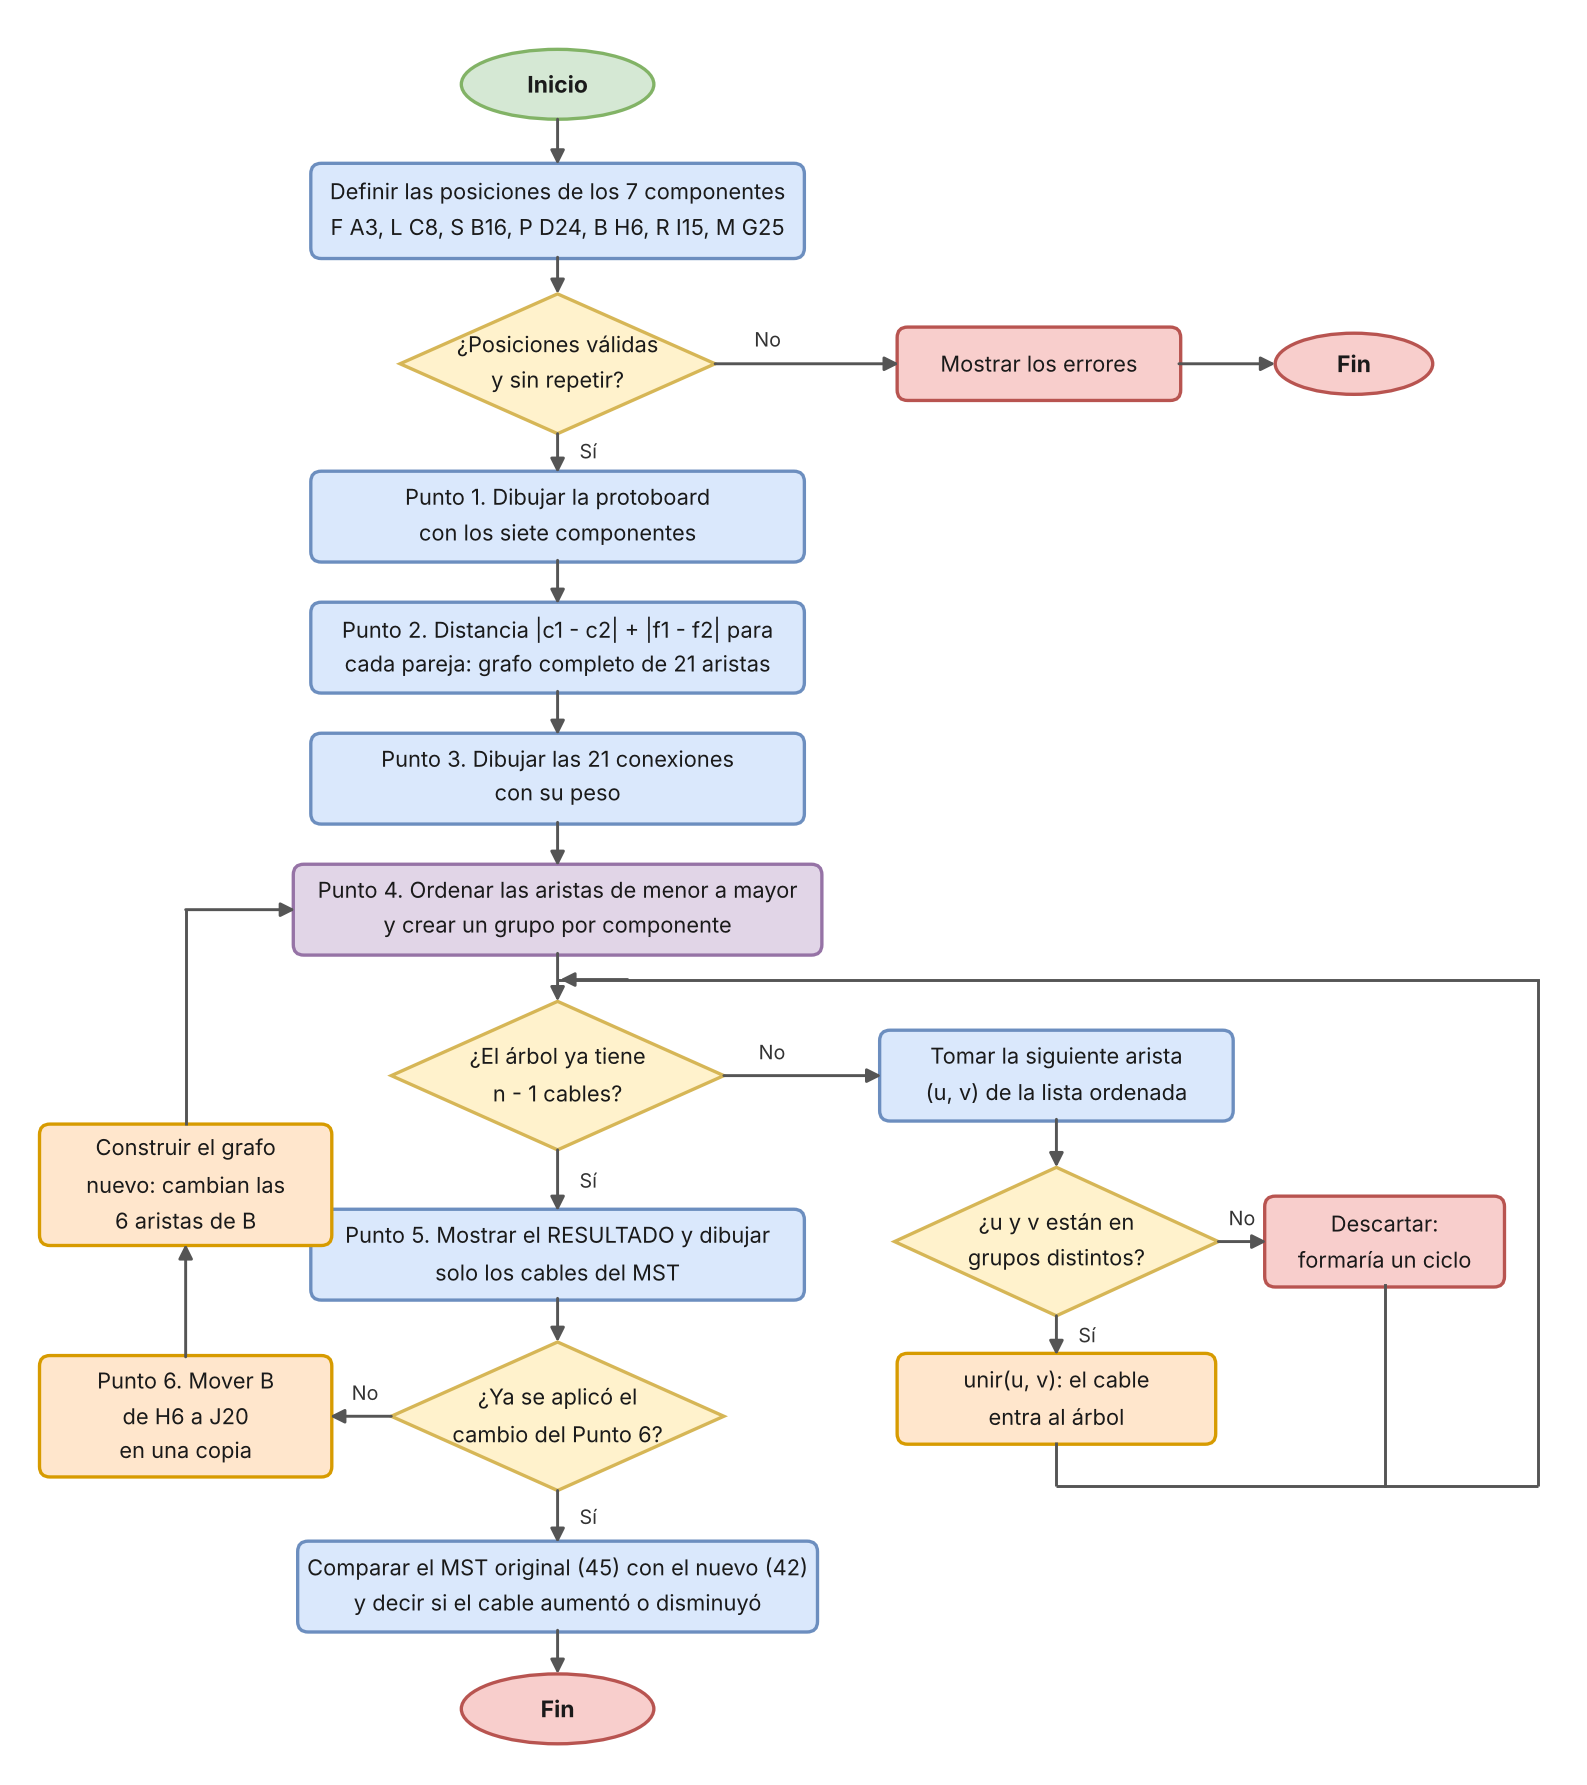

El programa valida primero las posiciones; si alguna es inválida, muestra el error y termina. Con posiciones válidas dibuja la protoboard (Punto 1), construye el grafo con las distancias (Punto 2) y dibuja las 21 conexiones (Punto 3). En el Punto 4 ordena las aristas y repite el ciclo de Kruskal: toma la siguiente arista, la agrega si une grupos distintos y la descarta si formaría un ciclo, hasta tener n - 1 cables. Luego muestra el resultado (Punto 5). La primera vez que llega a la última decisión, mueve el Buzzer a J20 en una copia, reconstruye el grafo y vuelve al Punto 4; la segunda vez compara las dos longitudes y termina.

### Diagrama de secuencia

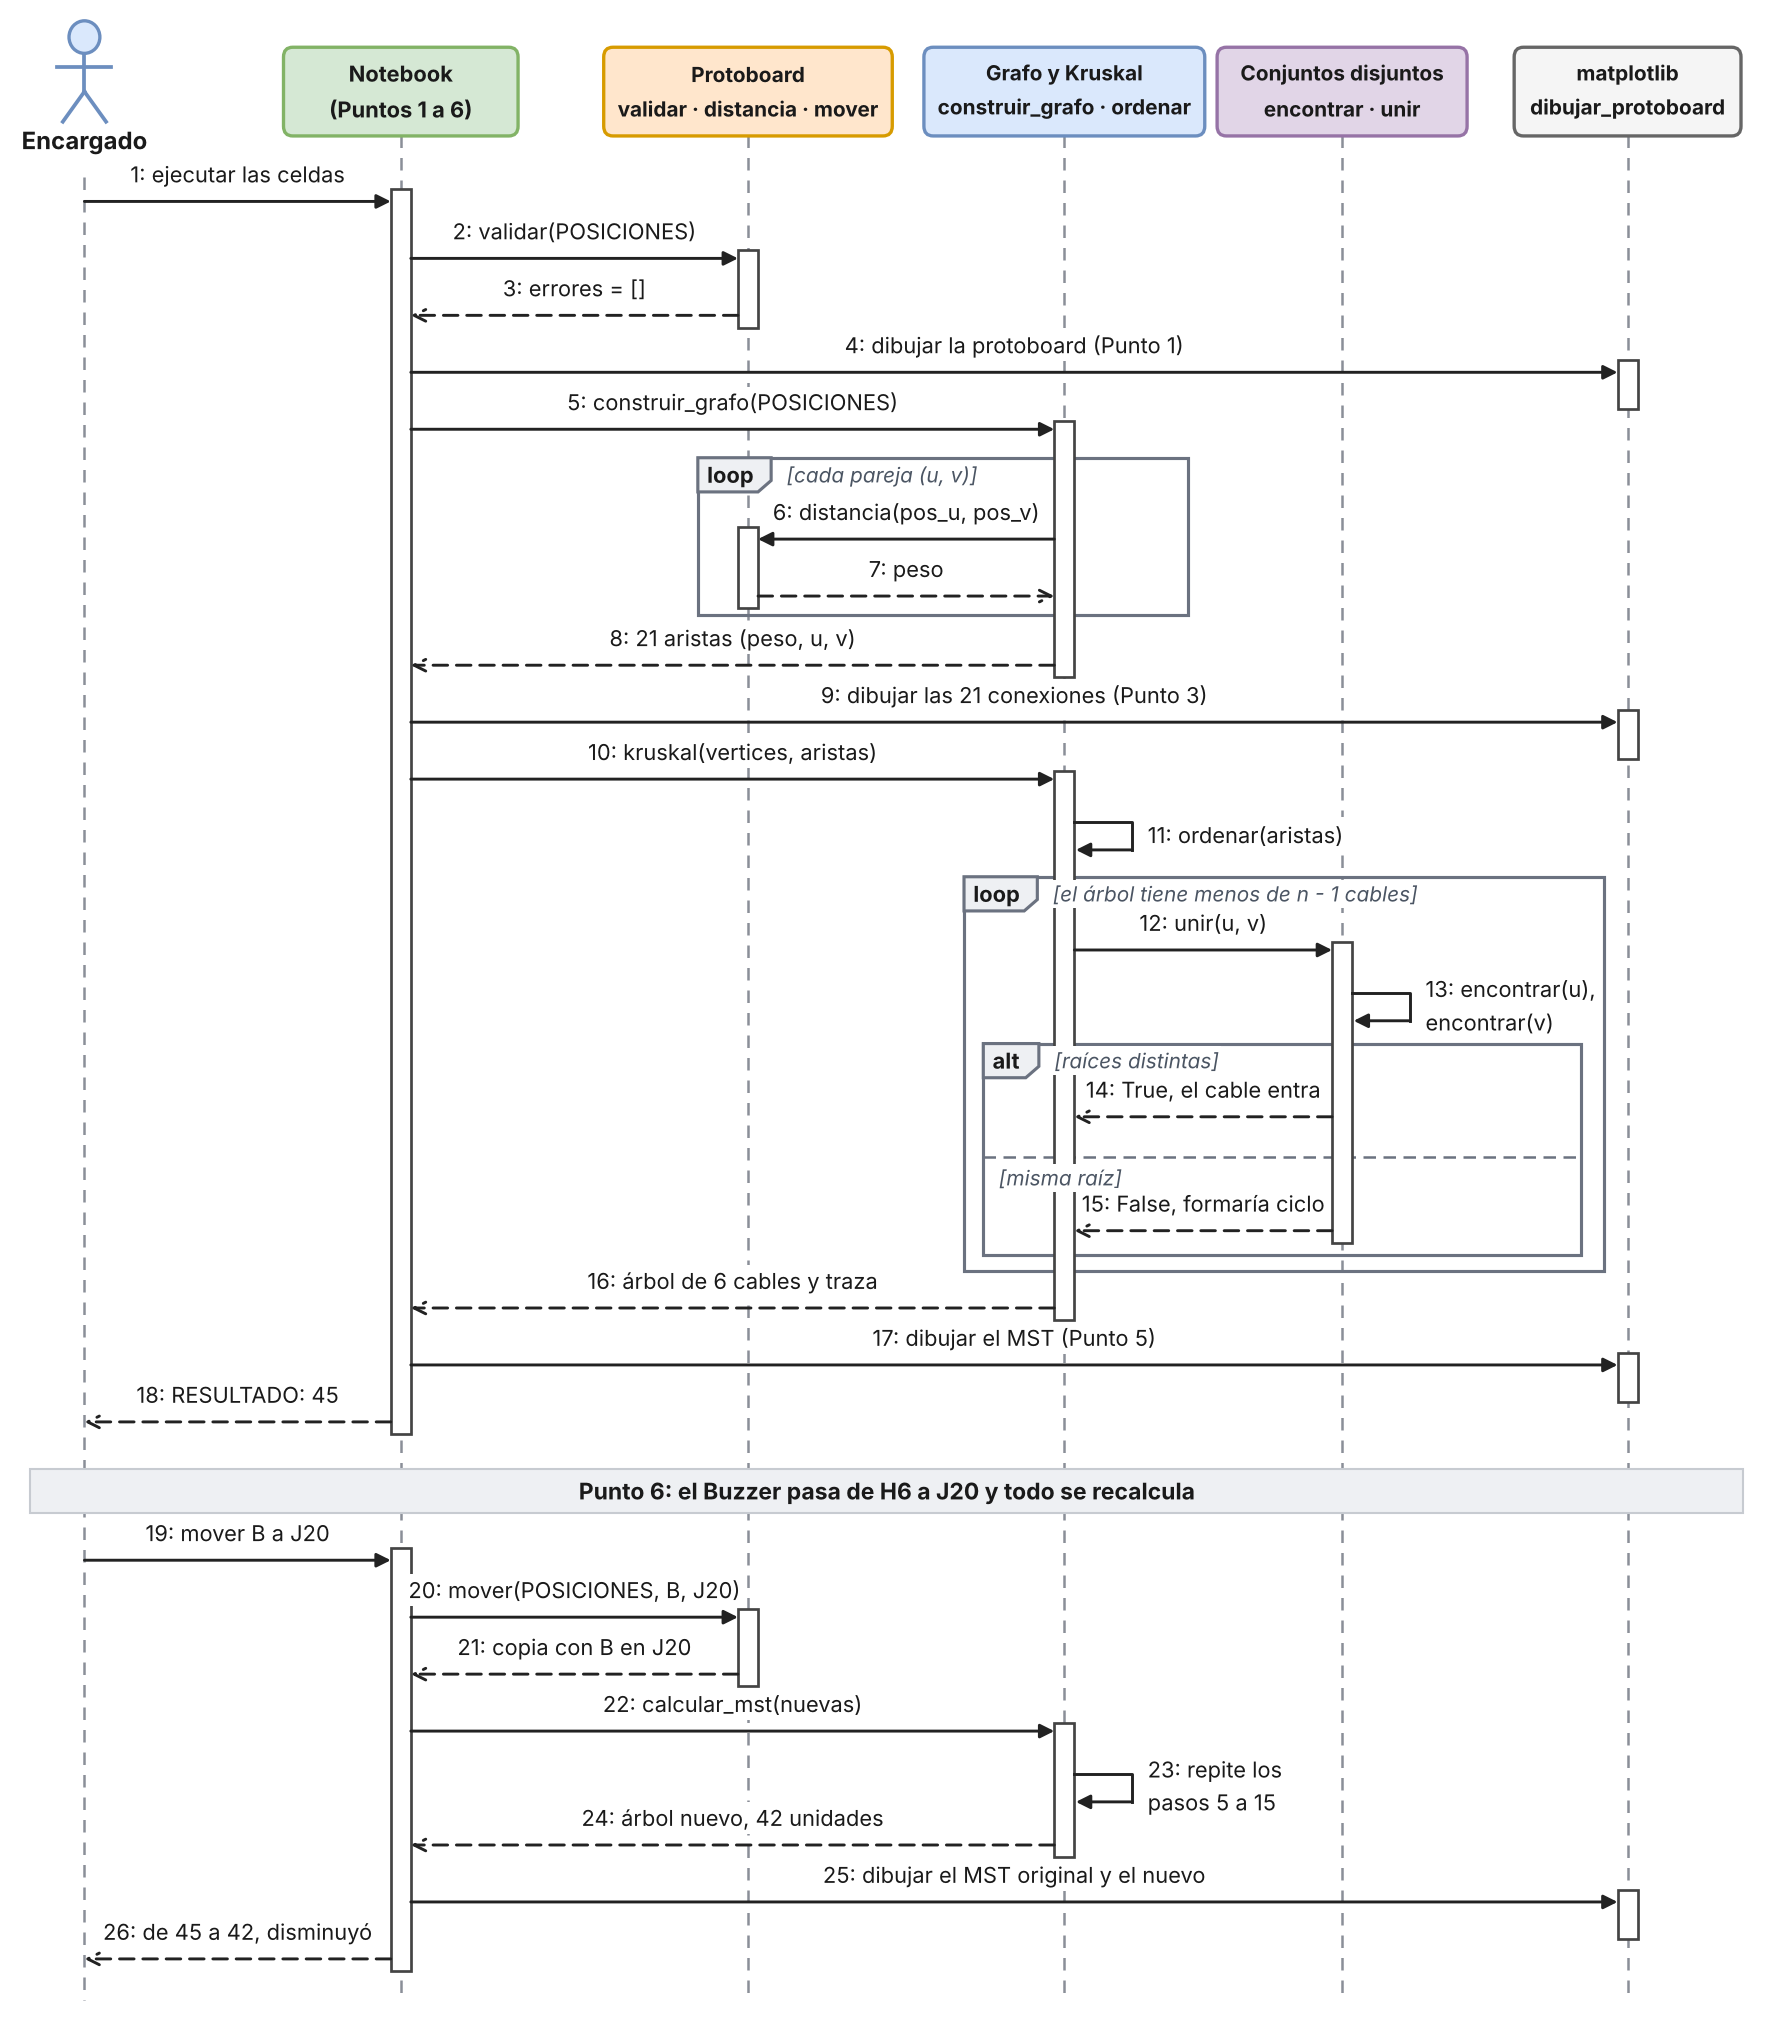

El encargado ejecuta el notebook. El notebook valida las posiciones, pide a matplotlib el dibujo inicial y pide al grafo las 21 aristas; para cada pareja se calcula la distancia (primer `loop`). Después llama a `kruskal`, que ordena las aristas y, mientras el árbol tenga menos de n - 1 cables, llama a `unir(u, v)`. Los conjuntos disjuntos comparan las raíces con `encontrar`: si son distintas el cable entra al árbol y si son iguales se descarta (bloque `alt`). En el Punto 6 el notebook mueve el Buzzer en una copia y llama a `calcular_mst`, que repite los pasos 5 a 15 con las nuevas posiciones.

### Diagrama de casos de uso

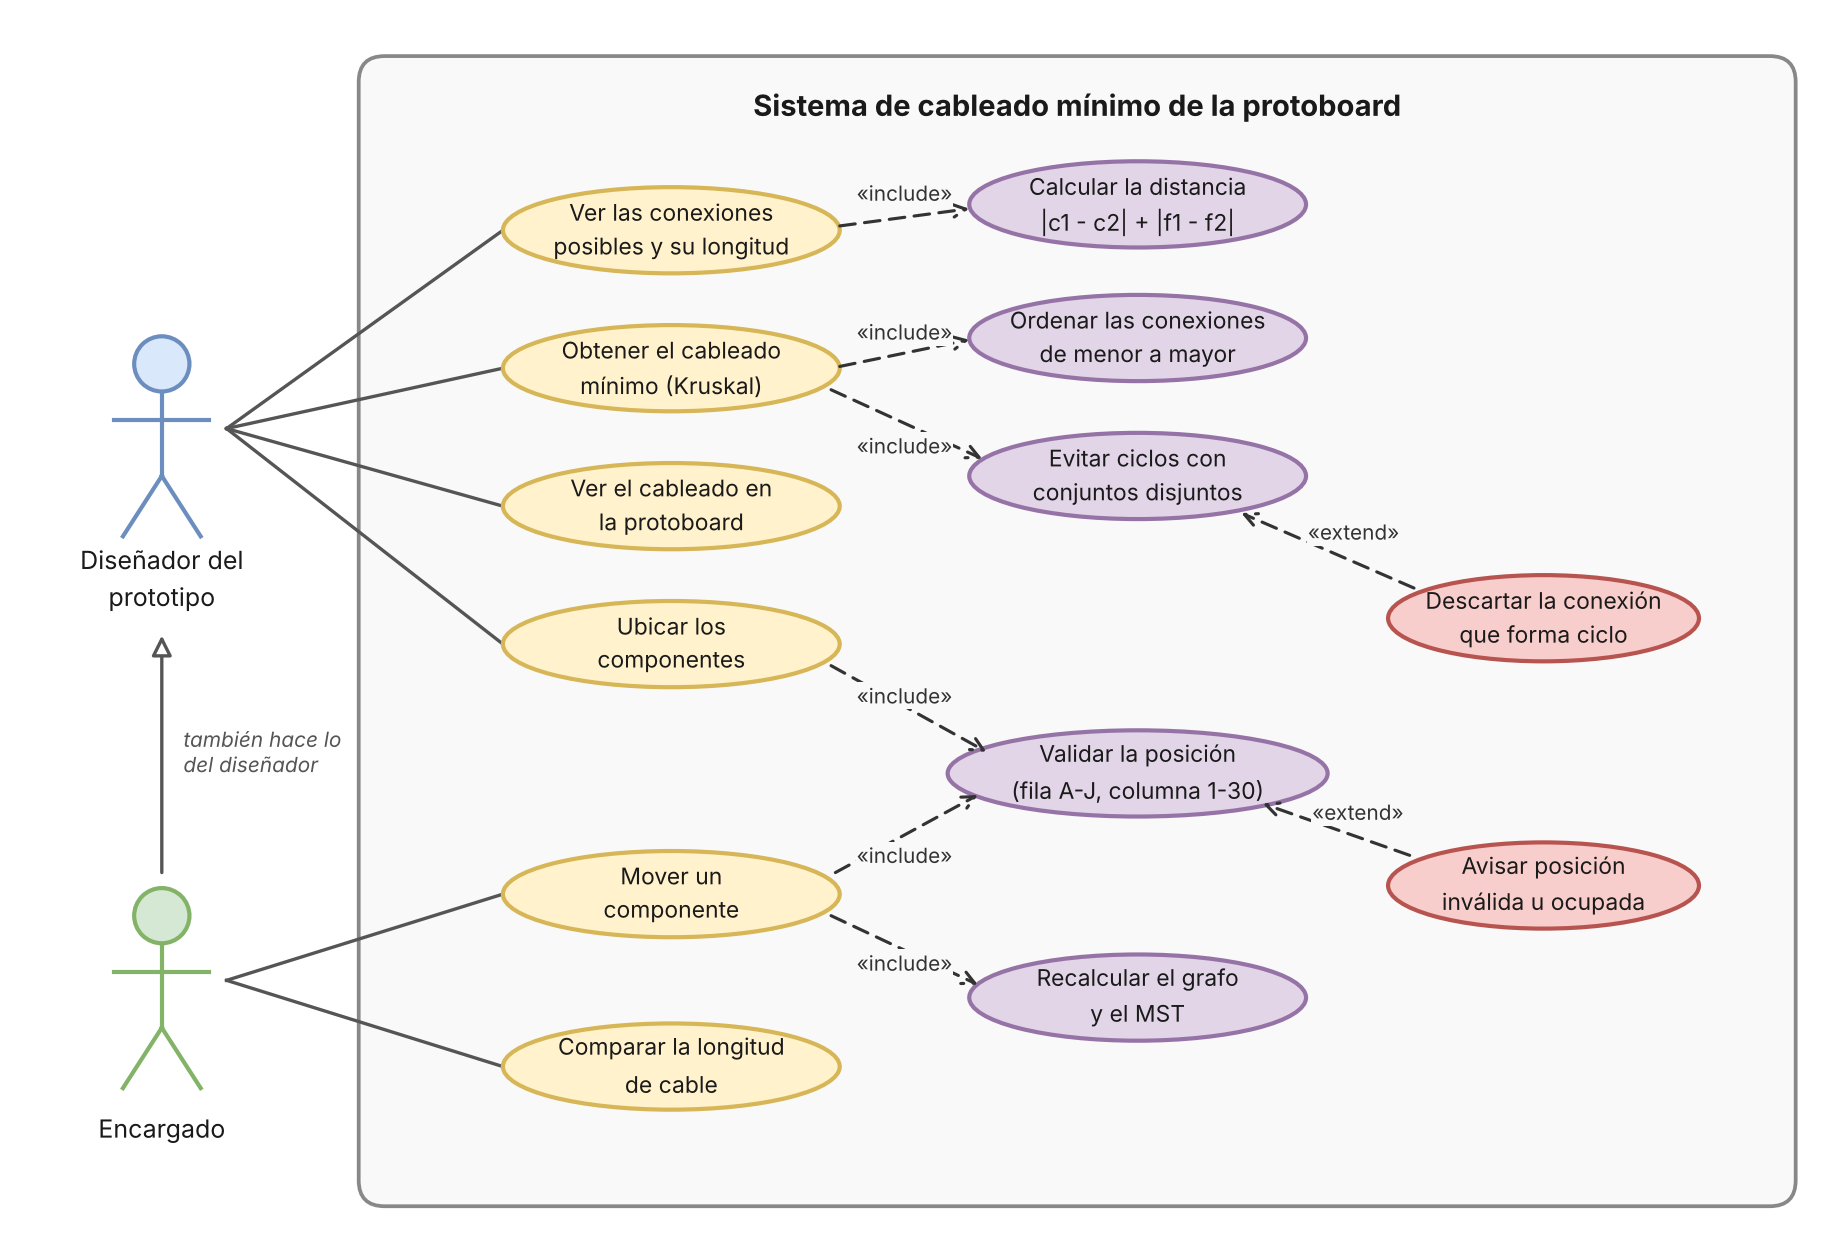

El diseñador ubica los componentes, ve las conexiones posibles, obtiene el cableado mínimo y lo ve en la protoboard. El encargado hereda esos casos y además mueve un componente y compara la longitud de cable. Los casos morados se ejecutan siempre que se ejecuta el caso que los incluye (`«include»`): obtener el cableado mínimo siempre ordena y evita ciclos, y mover un componente siempre valida la posición y recalcula el MST. Los casos rojos solo ocurren en ciertas condiciones (`«extend»`): descartar una conexión cuando formaría un ciclo y avisar cuando una posición es inválida u ocupada.

### 5) Análisis de complejidad **[15 pts]**

### Justificación

Sea $n$ el número de componentes y $E = n(n-1)/2$ el número de aristas del grafo completo. En el laboratorio $n = 7$ y $E = 21$.

| Función | Costo | Por qué |
|---|---|---|
| `posicion_valida`, `a_coordenadas`, `distancia` | $O(1)$ | trabajan sobre un texto de 2 o 3 caracteres; `FILAS.index` revisa a lo sumo 10 letras |
| `validar` | $O(n)$ | recorre los n componentes y consulta un diccionario en $O(1)$ |
| `mover` | $O(n)$ | copia el diccionario y lo valida |
| `construir_grafo` | $\Theta(n^2)$ | dos ciclos anidados recorren las $E$ parejas, cada una en $O(1)$ |
| `ordenar` (merge sort) | $\Theta(E \log E)$ | parte la lista a la mitad $\log_2 E$ veces y en cada nivel mezcla las $E$ aristas: $T(E) = 2T(E/2) + cE$ |
| `encontrar` y `unir` | $O(\alpha(n))$ amortizado | compresión de caminos y unión por rango; $\alpha(n) \le 4$ para cualquier n práctico. Sin esas dos mejoras, un `encontrar` podría costar $O(n)$ |
| ciclo de `kruskal` | $O(k \cdot \alpha(n))$ | revisa $k$ aristas, con $n - 1 \le k \le E$ |
| `conecta_todos` | $O(n)$ | recorre un árbol de n vértices y n - 1 aristas |
| `longitud` | $O(n)$ | suma n - 1 pesos |
| `mostrar_traza` | $O(k \cdot n)$ | arma los grupos de cada paso; solo sirve para mostrar y no hace parte de `kruskal` |
| `dibujar_protoboard` | $O(E^2)$ en el peor caso | cada etiqueta de peso se compara con las ya ubicadas; es parte gráfica, no del cálculo del MST |

### Conteo línea por línea

**`construir_grafo`.** Para cada `i`, el encabezado del ciclo interno se evalúa $n - i$ veces y su cuerpo $n - i - 1$ veces:

| Línea | Costo | Veces que se ejecuta |
|---|---|---|
| `comps = list(posiciones)` | $c_1 n$ | 1 |
| `aristas = []` | $c_2$ | 1 |
| `for i in range(len(comps))` | $c_3$ | $n + 1$ |
| `for j in range(i + 1, len(comps))` | $c_4$ | $\sum_{i=0}^{n-1} (n - i) = \frac{n(n+1)}{2}$ |
| `u, v = comps[i], comps[j]` | $c_5$ | $\sum_{i=0}^{n-1} (n - i - 1) = \frac{n(n-1)}{2}$ |
| `aristas.append((distancia(...), u, v))` | $c_6$ | $\frac{n(n-1)}{2}$ |
| `return aristas` | $c_7$ | 1 |

$$T_{\text{grafo}}(n) = c_1 n + c_3 (n + 1) + c_4 \frac{n(n+1)}{2} + (c_5 + c_6) \frac{n(n-1)}{2} + c_2 + c_7 = \Theta(n^2)$$

**`ordenar`.** Cada llamada parte la lista en dos mitades y luego las mezcla recorriendo los E elementos una vez:

$$T(E) = 2\,T\!\left(\frac{E}{2}\right) + cE, \qquad T(1) = c_0$$

Desenrollando $j$ veces: $T(E) = 2^j\, T\!\left(\frac{E}{2^j}\right) + j\,cE$. La recursión llega a listas de un elemento cuando $j = \log_2 E$, y queda

$$T(E) = c_0 E + cE \log_2 E = \Theta(E \log E)$$

**`kruskal`.** Sea $k$ el número de aristas que revisa el ciclo ($n - 1 \le k \le E$):

| Línea | Costo | Veces que se ejecuta |
|---|---|---|
| `padre, rango = crear_conjuntos(vertices)` | $c_1 n$ | 1 |
| `arbol, traza = [], []` | $c_2$ | 1 |
| `for peso, u, v in ordenar(aristas)` | $T_{\text{ord}}(E)$ una vez, más $c_3$ | $k + 1$ |
| `if len(arbol) == len(vertices) - 1: break` | $c_4$ | $k + 1$ |
| `aceptada = unir(padre, rango, u, v)` | $c_5\, \alpha(n)$ | $k$ |
| `traza.append((peso, u, v, aceptada))` | $c_6$ | $k$ |
| `if aceptada: arbol.append((peso, u, v))` | $c_7$ | $k$ (el `append` solo $n - 1$ veces) |
| `return arbol, traza` | $c_8$ | 1 |

$$T_{\text{kruskal}}(n) = T_{\text{ord}}(E) + (c_3 + c_4)(k + 1) + \left(c_5\, \alpha(n) + c_6 + c_7\right) k + c_1 n + c_2 + c_8$$

### Función T(n)

`calcular_mst` llama a `construir_grafo` y luego a `kruskal`, así que su costo es la suma de los dos conteos anteriores. Agrupando las constantes de las tablas en $C_1$, $C_2$ y $C_3$:

$$T(n) = \underbrace{C_1 E}_{\text{construir el grafo}} + \underbrace{C_2 E \log_2 E}_{\text{ordenar}} + \underbrace{C_3\, k\, \alpha(n)}_{\text{ciclo de Kruskal}} + O(n), \qquad E = \frac{n(n-1)}{2}$$

Como $\log_2 E < \log_2 n^2 = 2 \log_2 n$, el término del ordenamiento cumple $C_2 E \log_2 E < 2\,C_2\, n^2 \log_2 n$; y como $k \le E$ y $\alpha(n) \le 4$, el ciclo nunca pasa de $4\,C_3 E$. Por eso

$$T(n) = \Theta(n^2 \log n)$$

La recurrencia del merge sort también se resuelve con el caso 2 del teorema maestro: $a = 2$, $b = 2$ y $f(E) = \Theta(E) = \Theta(E^{\log_b a})$, así que $T(E) = \Theta(E \log E)$, igual que al desenrollarla.

**Memoria:** $O(E) = O(n^2)$ para la lista de aristas y su copia ordenada, más $O(n)$ para `padre` y `rango`.

### Mejor caso
El ciclo revisa solo $k = n - 1$ aristas: las $n - 1$ más livianas ya forman un árbol y ninguna se rechaza. Pasa, por ejemplo, con los componentes seguidos en una fila (A1, A2, A3, ...), donde las aristas de peso 1 forman un camino.

$$T_{\text{mejor}}(n) = C_1 E + C_2 E \log_2 E + C_3 (n - 1)\, \alpha(n) = \Theta(n^2 \log n)$$

### Peor caso
El ciclo revisa casi todas las aristas, $k \approx E$. Pasa cuando el último componente por conectar está lejos de todos, porque sus aristas son más pesadas que todas las demás. Por ejemplo, un bloque de componentes en una esquina y uno solo en J30.

$$T_{\text{peor}}(n) = C_1 E + C_2 E \log_2 E + C_3 E\, \alpha(n) = \Theta(n^2 \log n)$$

Entre el mejor y el peor caso el ciclo pasa de $\Theta(n)$ a $\Theta(n^2)$, pero el orden total no cambia porque ordenar ya cuesta $\Theta(n^2 \log n)$. En el laboratorio, Kruskal revisó 8 de las 21 aristas con la distribución original y 6 de 21 después del cambio, que es el mejor caso posible.

**Comparación con Prim.** En un grafo completo, Prim con arreglos cuesta $O(n^2)$, un poco menos que Kruskal. El enunciado pide Kruskal, y con n ≤ 300 (lo máximo que cabe en la protoboard) la diferencia es de milisegundos. Una búsqueda por fuerza bruta, en cambio, tendría que revisar $n^{n-2}$ árboles.

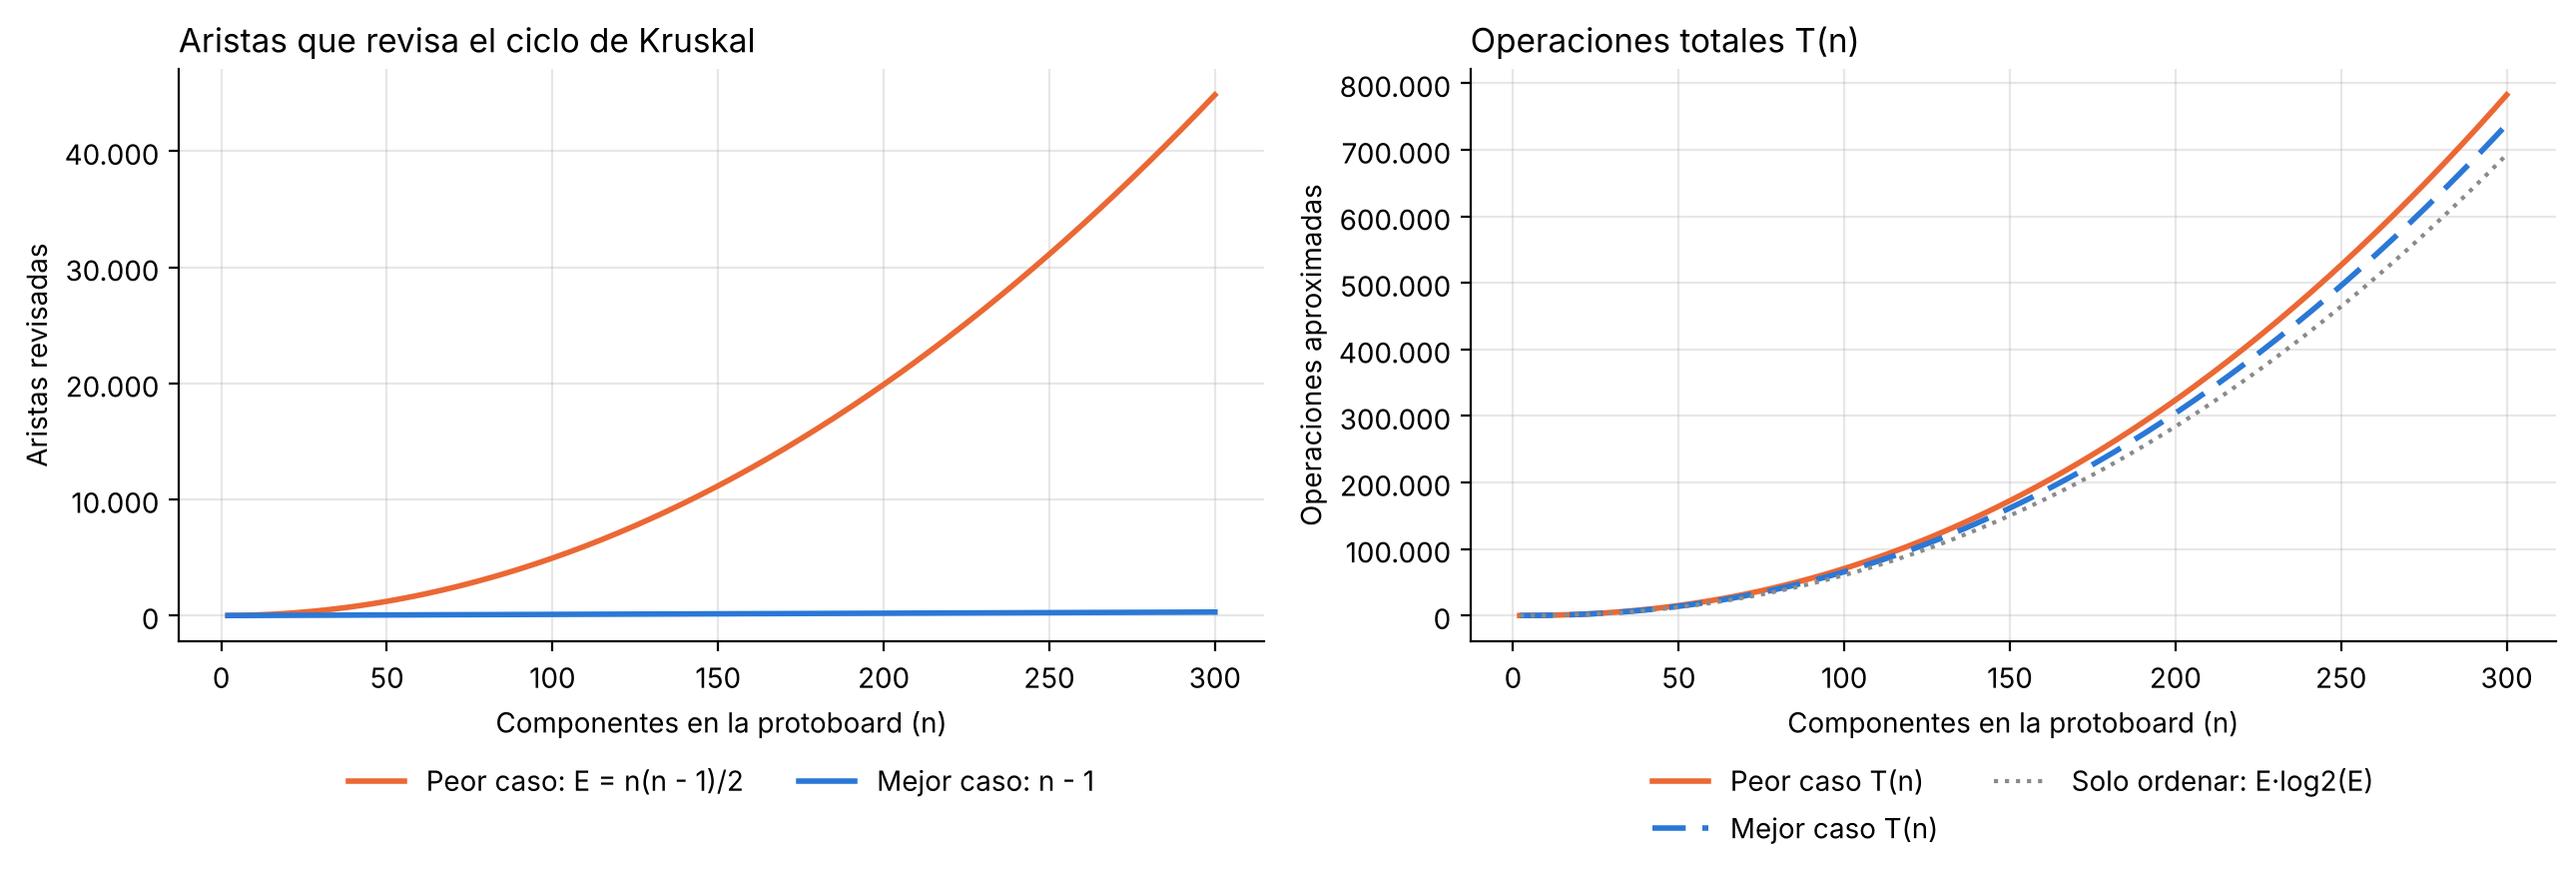

In [2]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(2, 301)
E = n * (n - 1) / 2
ordenar_E = E * np.log2(E)
mejor = E + ordenar_E + (n - 1)
peor = E + ordenar_E + E
miles = plt.FuncFormatter(lambda valor, pos: f"{valor:,.0f}".replace(",", "."))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
ax1.plot(n, E, color="#eb6834", lw=2, label="Peor caso: E = n(n - 1)/2")
ax1.plot(n, n - 1, color="#2a78d6", lw=2, label="Mejor caso: n - 1")
ax1.set_title("Aristas que revisa el ciclo de Kruskal", loc="left")
ax1.set_ylabel("Aristas revisadas")
ax2.plot(n, peor, color="#eb6834", lw=2, label="Peor caso T(n)")
ax2.plot(n, mejor, color="#2a78d6", lw=2, ls=(0, (6, 3)), label="Mejor caso T(n)")
ax2.plot(n, ordenar_E, color="#8a8a8a", lw=1.5, ls=":", label="Solo ordenar: E·log2(E)")
ax2.set_title("Operaciones totales T(n)", loc="left")
ax2.set_ylabel("Operaciones aproximadas")
for ax in (ax1, ax2):
    ax.set_xlabel("Componentes en la protoboard (n)")
    ax.yaxis.set_major_formatter(miles)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

La gráfica de la izquierda muestra la diferencia entre los dos casos dentro del ciclo: n - 1 aristas contra n(n - 1)/2. La de la derecha muestra que en el tiempo total esa diferencia casi no se nota: las dos curvas de T(n) quedan pegadas a la de ordenar, porque el merge sort domina y los dos casos son $\Theta(n^2 \log n)$.

## 6) Código funcional **[15 pts]**

El código está dividido en cinco celdas de funciones y seis celdas de ejecución, una por punto del enunciado. Cada arista se guarda como una tupla `(peso, u, v)`: al ordenar las tuplas quedan ordenadas por peso, y los empates se resuelven por las letras de los componentes. No se usa ninguna librería de grafos.

### Datos del problema
`FILAS` guarda las letras en orden, así que la posición de una letra en ese texto da su número de fila. `NOMBRES` y `POSICIONES` usan el identificador de cada componente como llave.

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

plt.rcParams["mathtext.default"] = "regular"

FILAS = "ABCDEFGHIJ"
COLUMNAS = 30

NOMBRES = {
    "F": "Fuente de alimentación",
    "L": "LED",
    "S": "Sensor",
    "P": "Pulsador",
    "B": "Buzzer",
    "R": "Potenciómetro",
    "M": "Microcontrolador",
}

POSICIONES = {"F": "A3", "L": "C8", "S": "B16", "P": "D24", "B": "H6", "R": "I15", "M": "G25"}

### Posiciones y distancia

| Función | Entrada | Salida |
|---|---|---|
| `posicion_valida(pos)` | texto como `"A3"` | `True` si la fila está entre A y J y la columna entre 1 y 30 |
| `a_coordenadas(pos)` | posición válida | `(columna, fila)`; por ejemplo `"A3"` da `(3, 1)` |
| `distancia(p, q)` | dos posiciones | $\lvert c_1 - c_2 \rvert + \lvert f_1 - f_2 \rvert$ |
| `validar(posiciones)` | distribución | lista de errores, vacía si todo está bien |
| `mover(posiciones, comp, nueva)` | distribución, componente y nueva posición | copia con el cambio, o `None` si el cambio no es válido |
| `protoboard_texto(posiciones)` | distribución | la protoboard en texto, con `·` en las perforaciones libres |

`posicion_valida` usa `isascii()` además de `isdigit()` porque `"³".isdigit()` es `True` en Python e `int("³")` falla, y rechaza los ceros a la izquierda para que `"A03"` no pase como otra forma de escribir `"A3"`.

In [4]:
def posicion_valida(pos):
    if not isinstance(pos, str) or len(pos) < 2:
        return False
    fila, columna = pos[0], pos[1:]
    if fila not in FILAS or not columna.isascii() or not columna.isdigit() or columna[0] == "0":
        return False
    return int(columna) <= COLUMNAS


def a_coordenadas(pos):
    return int(pos[1:]), FILAS.index(pos[0]) + 1


def distancia(p, q):
    c1, f1 = a_coordenadas(p)
    c2, f2 = a_coordenadas(q)
    return abs(c1 - c2) + abs(f1 - f2)


def validar(posiciones):
    errores = []
    usadas = {}
    for comp, pos in posiciones.items():
        if not posicion_valida(pos):
            errores.append(f"{comp}: la posición {pos!r} no existe en la protoboard")
        elif pos in usadas:
            errores.append(f"{comp}: la posición {pos} ya la ocupa {usadas[pos]}")
        else:
            usadas[pos] = comp
    return errores


def mover(posiciones, comp, nueva):
    if comp not in posiciones:
        return None
    copia = dict(posiciones)
    copia[comp] = nueva
    if validar(copia):
        return None
    return copia


def protoboard_texto(posiciones):
    ocupadas = {pos: comp for comp, pos in posiciones.items()}
    lineas = ["  " + "".join(f"{c:>3}" for c in range(1, COLUMNAS + 1))]
    for fila in FILAS:
        celdas = [ocupadas.get(f"{fila}{c}", "·") for c in range(1, COLUMNAS + 1)]
        lineas.append(f"{fila:<2}" + "".join(f"{x:>3}" for x in celdas))
    return "\n".join(lineas)

### Grafo y algoritmo de Kruskal

| Función | Entrada | Salida |
|---|---|---|
| `construir_grafo(posiciones)` | distribución | lista de las $n(n-1)/2$ aristas `(peso, u, v)` |
| `ordenar(aristas)` | lista de aristas | lista nueva, ordenada con merge sort de menor a mayor |
| `crear_conjuntos(vertices)` | vértices | `padre` (cada vértice es su propia raíz) y `rango` (todo en 0) |
| `encontrar(padre, x)` | vértice | raíz del grupo de x; de paso deja a x apuntando directo a la raíz |
| `unir(padre, rango, a, b)` | dos vértices | `True` si estaban en grupos distintos y los unió; `False` si ya estaban juntos |
| `kruskal(vertices, aristas)` | vértices y aristas | `arbol` con los cables elegidos y `traza` con cada arista revisada |
| `longitud(arbol)` | lista de aristas | suma de los pesos |
| `conecta_todos(vertices, arbol)` | vértices y aristas | `True` si desde el primer vértice se llega a todos |
| `calcular_mst(posiciones)` | distribución | `(aristas, arbol, traza)`; es lo que se vuelve a llamar en el Punto 6 |

La clave está en `unir`: si dos vértices tienen la misma raíz ya están conectados, y una arista entre ellos cerraría un ciclo. El ciclo de `kruskal` termina apenas el árbol tiene n - 1 cables, sin revisar el resto de la lista.

In [5]:
def construir_grafo(posiciones):
    comps = list(posiciones)
    aristas = []
    for i in range(len(comps)):
        for j in range(i + 1, len(comps)):
            u, v = comps[i], comps[j]
            aristas.append((distancia(posiciones[u], posiciones[v]), u, v))
    return aristas


def ordenar(aristas):
    if len(aristas) <= 1:
        return list(aristas)
    medio = len(aristas) // 2
    izq = ordenar(aristas[:medio])
    der = ordenar(aristas[medio:])
    res = []
    i = j = 0
    while i < len(izq) and j < len(der):
        if izq[i] <= der[j]:
            res.append(izq[i])
            i += 1
        else:
            res.append(der[j])
            j += 1
    return res + izq[i:] + der[j:]


def crear_conjuntos(vertices):
    return {v: v for v in vertices}, {v: 0 for v in vertices}


def encontrar(padre, x):
    if padre[x] != x:
        padre[x] = encontrar(padre, padre[x])
    return padre[x]


def unir(padre, rango, a, b):
    ra, rb = encontrar(padre, a), encontrar(padre, b)
    if ra == rb:
        return False
    if rango[ra] < rango[rb]:
        ra, rb = rb, ra
    padre[rb] = ra
    if rango[ra] == rango[rb]:
        rango[ra] += 1
    return True


def kruskal(vertices, aristas):
    padre, rango = crear_conjuntos(vertices)
    arbol, traza = [], []
    for peso, u, v in ordenar(aristas):
        if len(arbol) == len(vertices) - 1:
            break
        aceptada = unir(padre, rango, u, v)
        traza.append((peso, u, v, aceptada))
        if aceptada:
            arbol.append((peso, u, v))
    return arbol, traza


def longitud(arbol):
    return sum(peso for peso, u, v in arbol)


def conecta_todos(vertices, arbol):
    vertices = list(vertices)
    if not vertices:
        return True
    vecinos = {v: [] for v in vertices}
    for peso, u, v in arbol:
        vecinos[u].append(v)
        vecinos[v].append(u)
    vistos = {vertices[0]}
    pila = [vertices[0]]
    while pila:
        x = pila.pop()
        for y in vecinos[x]:
            if y not in vistos:
                vistos.add(y)
                pila.append(y)
    return len(vistos) == len(vertices)


def calcular_mst(posiciones):
    aristas = construir_grafo(posiciones)
    arbol, traza = kruskal(list(posiciones), aristas)
    return aristas, arbol, traza

### Salidas de texto
`mostrar_matriz` imprime la matriz de distancias, `mostrar_traza` repite el recorrido de Kruskal con conjuntos nuevos para mostrar qué grupos une cada cable, y `mostrar_resultado` imprime el bloque `RESULTADO` con el formato del enunciado. `mostrar_traza` solo sirve para explicar el recorrido; no hace parte del costo de `kruskal`.

In [6]:
def mostrar_matriz(posiciones):
    comps = list(posiciones)
    print("     " + "".join(f"{c:>4}" for c in comps))
    for u in comps:
        fila = "".join(f"{distancia(posiciones[u], posiciones[v]):>4}" for v in comps)
        print(f"{u:>5}{fila}")


def grupo(padre, vertices, x):
    raiz = encontrar(padre, x)
    return "{" + ", ".join(sorted(v for v in vertices if encontrar(padre, v) == raiz)) + "}"


def mostrar_traza(vertices, traza):
    padre, rango = crear_conjuntos(vertices)
    print(f"{'Paso':<6}{'Cable':<8}{'Peso':>4}   {'Decisión':<12}Detalle")
    for k, (peso, u, v, aceptada) in enumerate(traza, 1):
        gu, gv = grupo(padre, vertices, u), grupo(padre, vertices, v)
        if aceptada:
            unir(padre, rango, u, v)
            detalle = f"une {gu} con {gv}"
        else:
            detalle = f"{u} y {v} ya están en {gu}: formaría un ciclo"
        cable = f"{u} - {v}"
        decision = "aceptada" if aceptada else "rechazada"
        print(f"{k:02d}    {cable:<8}{peso:>4}   {decision:<12}{detalle}")


def mostrar_resultado(arbol):
    print(f"{' RESULTADO ':=^31}")
    for i, (peso, u, v) in enumerate(arbol, 1):
        print(f"Cable {i}: {u} - {v} = {peso}")
    print(f"Longitud total de cable: {longitud(arbol)} unidades")

### Dibujo de la protoboard
`dibujar_protoboard` recibe un eje de matplotlib, la distribución y un título. Con `todas` dibuja conexiones grises con su peso (Punto 3), con `mst` dibuja en naranja y en grueso solo los cables elegidos (Puntos 5 y 6) y con `anterior` marca la posición vieja de un componente. `lugar_etiqueta` corre cada número sobre su línea hasta encontrar un sitio libre, para que los pesos no se tapen entre sí. La franja gris entre E y F es el canal central de la protoboard; es solo visual y no cambia las distancias.

In [7]:
FONDO = "#f7f5ef"
HUECO = "#cdc7b8"
TINTA = "#222222"
CABLE = "#d4622a"
GRIS = "#8a8a8a"


def lugar_etiqueta(p, q, ocupados):
    for t in (0.5, 0.4, 0.6, 0.3, 0.7, 0.2, 0.8):
        x = p[0] + t * (q[0] - p[0])
        y = p[1] + t * (q[1] - p[1])
        if all(abs(x - a) > 0.9 or abs(y - b) > 0.6 for a, b in ocupados):
            ocupados.append((x, y))
            return x, y
    x, y = (p[0] + q[0]) / 2, (p[1] + q[1]) / 2
    ocupados.append((x, y))
    return x, y


def dibujar_protoboard(ax, posiciones, titulo, todas=(), mst=(), anterior=None):
    ax.set_facecolor(FONDO)
    ax.set_xlim(0.3, COLUMNAS + 0.7)
    ax.set_ylim(len(FILAS) + 0.7, 0.3)
    ax.set_aspect("equal")
    ax.axhspan(5.4, 5.6, color="#e3ded1", zorder=0)
    for f in range(1, len(FILAS) + 1):
        ax.scatter(range(1, COLUMNAS + 1), [f] * COLUMNAS, s=10, color=HUECO, zorder=1)
    ax.set_xticks(range(1, COLUMNAS + 1))
    ax.set_yticks(range(1, len(FILAS) + 1), list(FILAS))
    ax.xaxis.tick_top()
    ax.tick_params(length=0, labelsize=8.5, labelcolor="#555555")
    for borde in ax.spines.values():
        borde.set_visible(False)
    puntos = {c: a_coordenadas(p) for c, p in posiciones.items()}
    ocupados = list(puntos.values())
    contorno = [pe.withStroke(linewidth=3, foreground=FONDO)]
    for peso, u, v in mst:
        (x1, y1), (x2, y2) = puntos[u], puntos[v]
        ax.plot([x1, x2], [y1, y2], color=CABLE, lw=3.2, solid_capstyle="round", zorder=3)
        x, y = lugar_etiqueta(puntos[u], puntos[v], ocupados)
        ax.text(x, y, str(peso), ha="center", va="center", fontsize=10.5, fontweight="bold",
                color=TINTA, path_effects=contorno, zorder=6)
    for peso, u, v in todas:
        (x1, y1), (x2, y2) = puntos[u], puntos[v]
        ax.plot([x1, x2], [y1, y2], color=GRIS, lw=1, alpha=0.7, zorder=2)
        x, y = lugar_etiqueta(puntos[u], puntos[v], ocupados)
        ax.text(x, y, str(peso), ha="center", va="center", fontsize=9, color=TINTA,
                path_effects=contorno, zorder=6)
    if anterior:
        ax.add_patch(plt.Circle(a_coordenadas(anterior), 0.38, fill=False, ec=TINTA, lw=1.3, ls="--", zorder=4))
    for comp, (x, y) in puntos.items():
        ax.add_patch(plt.Circle((x, y), 0.4, color=TINTA, zorder=5))
        ax.text(x, y, comp, ha="center", va="center", color="white", fontsize=10, fontweight="bold", zorder=6)
    ax.set_title(titulo, loc="left", fontsize=12.5, pad=26)


def leyenda(ax, posiciones, extra=()):
    simbolos, textos = [], []
    for comp, pos in posiciones.items():
        circulo = Line2D([], [], marker="o", ls="", ms=15, color=TINTA)
        letra = Line2D([], [], marker=f"${comp}$", ls="", ms=7, color="white")
        simbolos.append((circulo, letra))
        textos.append(f"{NOMBRES[comp]} ({pos})")
    for simbolo, texto in extra:
        simbolos.append(simbolo)
        textos.append(texto)
    ax.legend(simbolos, textos, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=(len(textos) + 1) // 2,
              frameon=False, fontsize=9.5, handlelength=1.6, columnspacing=1.4)

### Punto 1. Construcción visual de la protoboard
Primero se validan las posiciones y se imprime la protoboard en texto, como en el enunciado; después se dibuja con matplotlib.

Distribución válida: 7 componentes en perforaciones distintas

    1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30
A   ·  ·  F  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·
B   ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  S  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·
C   ·  ·  ·  ·  ·  ·  ·  L  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·
D   ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  P  ·  ·  ·  ·  ·  ·
E   ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·
F   ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·
G   ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  M  ·  ·  ·  ·  ·
H   ·  ·  ·  ·  ·  B  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·
I   ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  R  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·
J   ·  

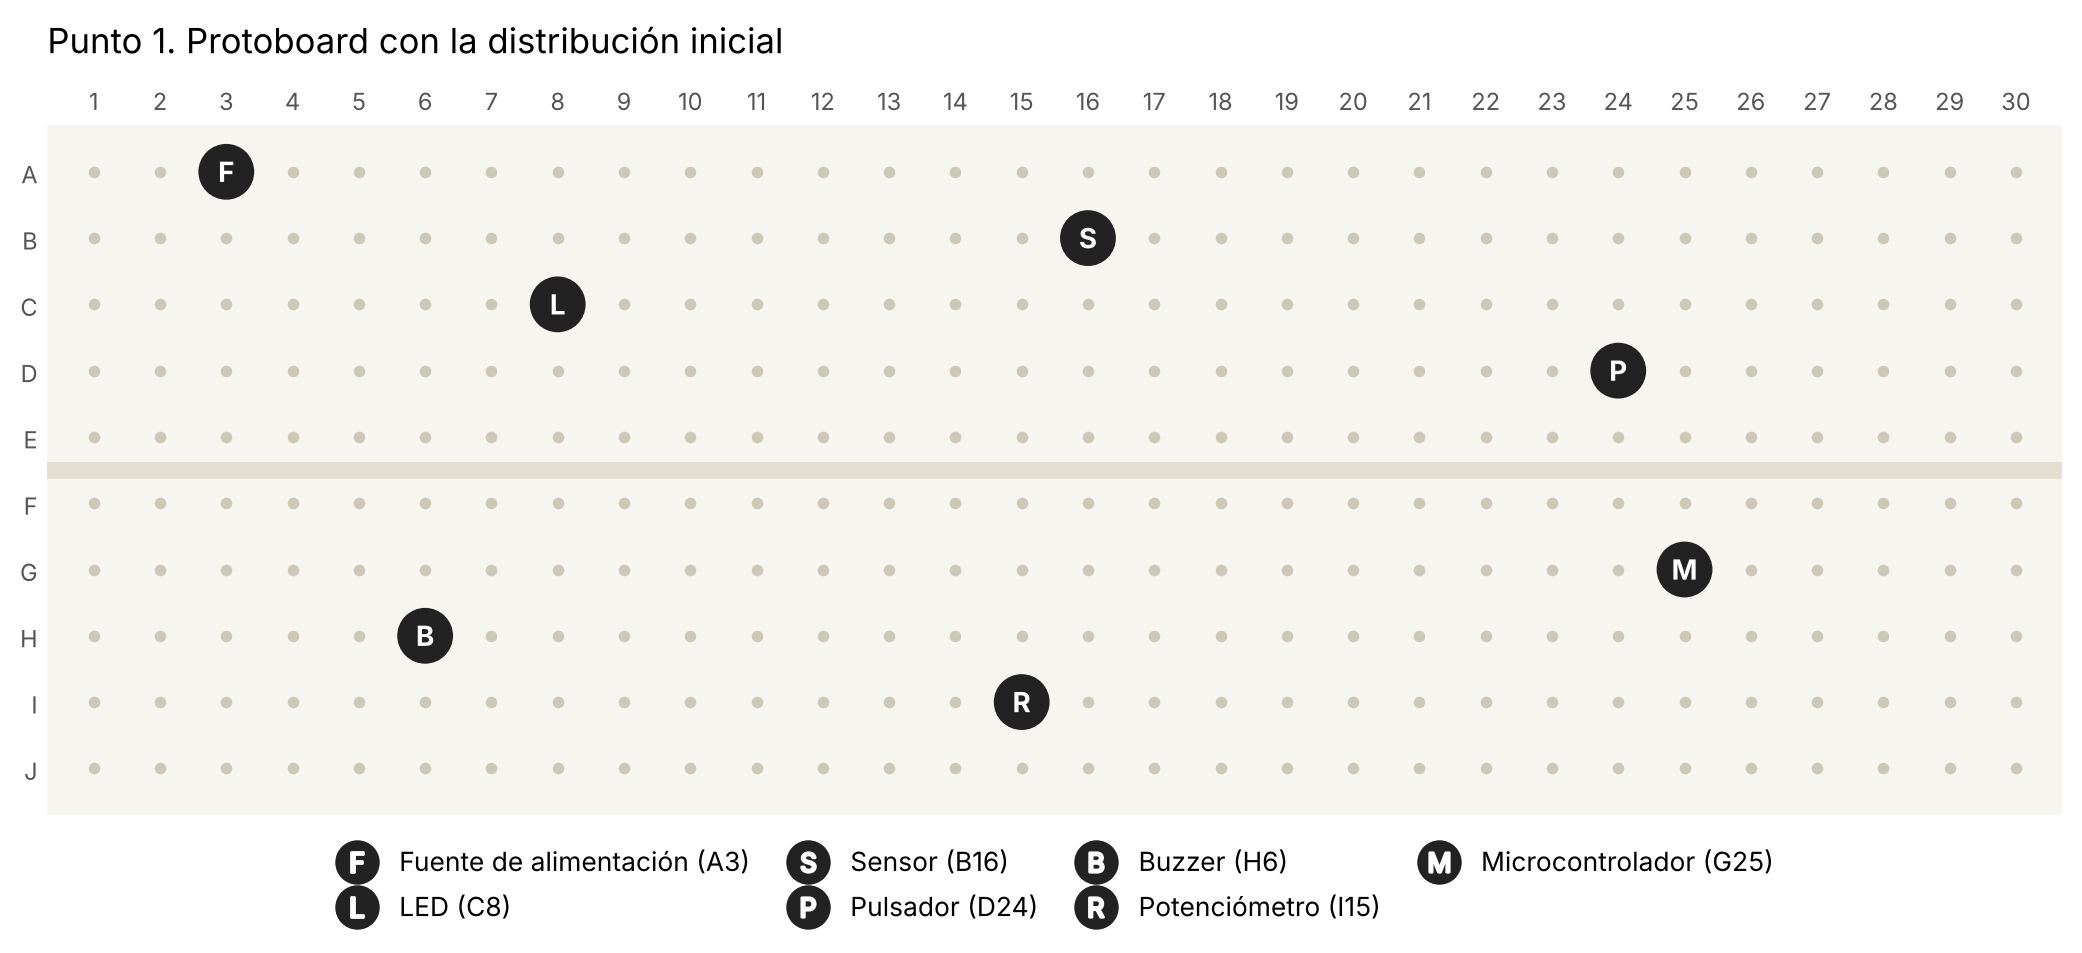

In [8]:
errores = validar(POSICIONES)
if errores:
    print("\n".join(errores))
else:
    print(f"Distribución válida: {len(POSICIONES)} componentes en perforaciones distintas\n")
print(protoboard_texto(POSICIONES))

fig, ax = plt.subplots(figsize=(13, 5.4))
dibujar_protoboard(ax, POSICIONES, "Punto 1. Protoboard con la distribución inicial")
leyenda(ax, POSICIONES)
plt.show()

### Punto 2. Construcción del grafo
Cada componente es un vértice y cada pareja es una arista. El programa imprime las coordenadas, recalcula los tres ejemplos del enunciado, muestra la matriz de distancias y lista las 21 aristas.

In [9]:
vertices = list(POSICIONES)
aristas = construir_grafo(POSICIONES)
ancho = max(len(nombre) for nombre in NOMBRES.values())

print(f"{'Componente':<{ancho}}  {'Id':^4}{'Posición':^10}{'(columna, fila)':>16}")
for comp, pos in POSICIONES.items():
    c, f = a_coordenadas(pos)
    print(f"{NOMBRES[comp]:<{ancho}}  {comp:^4}{pos:^10}{f'({c}, {f})':>16}")

print("\nEjemplos del enunciado, calculados por el programa:")
for u, v in [("F", "L"), ("L", "S"), ("S", "P")]:
    c1, f1 = a_coordenadas(POSICIONES[u])
    c2, f2 = a_coordenadas(POSICIONES[v])
    d = distancia(POSICIONES[u], POSICIONES[v])
    print(f"{u} = {f'({c1}, {f1})':<10}{v} = {f'({c2}, {f2})':<10}", end="")
    print(f"distancia = |{c1} - {c2}| + |{f1} - {f2}| = {abs(c1 - c2)} + {abs(f1 - f2)} = {d}")

print("\nMatriz de distancias:")
mostrar_matriz(POSICIONES)

print(f"\nGrafo: {len(vertices)} vértices y {len(aristas)} aristas")
for i in range(0, len(aristas), 3):
    print("    ".join(f"{u} {f' {peso} ':-^19} {v}" for peso, u, v in aristas[i:i + 3]))

Componente               Id  Posición  (columna, fila)
Fuente de alimentación   F      A3              (3, 1)
LED                      L      C8              (8, 3)
Sensor                   S     B16             (16, 2)
Pulsador                 P     D24             (24, 4)
Buzzer                   B      H6              (6, 8)
Potenciómetro            R     I15             (15, 9)
Microcontrolador         M     G25             (25, 7)

Ejemplos del enunciado, calculados por el programa:
F = (3, 1)    L = (8, 3)    distancia = |3 - 8| + |1 - 3| = 5 + 2 = 7
L = (8, 3)    S = (16, 2)   distancia = |8 - 16| + |3 - 2| = 8 + 1 = 9
S = (16, 2)   P = (24, 4)   distancia = |16 - 24| + |2 - 4| = 8 + 2 = 10

Matriz de distancias:
        F   L   S   P   B   R   M
    F   0   7  14  24  10  20  28
    L   7   0   9  17   7  13  21
    S  14   9   0  10  16   8  14
    P  24  17  10   0  22  14   4
    B  10   7  16  22   0  10  20
    R  20  13   8  14  10   0  12
    M  28  21  14   4  20  12   

### Punto 3. Mostrar todas las posibles conexiones
Se dibujan las 21 aristas sobre la protoboard con el peso que calculó `construir_grafo`; ningún número está escrito a mano.

Conexiones posibles: n(n - 1)/2 = 7·6/2 = 21
Si se pusieran todas, harían falta 300 unidades de cable


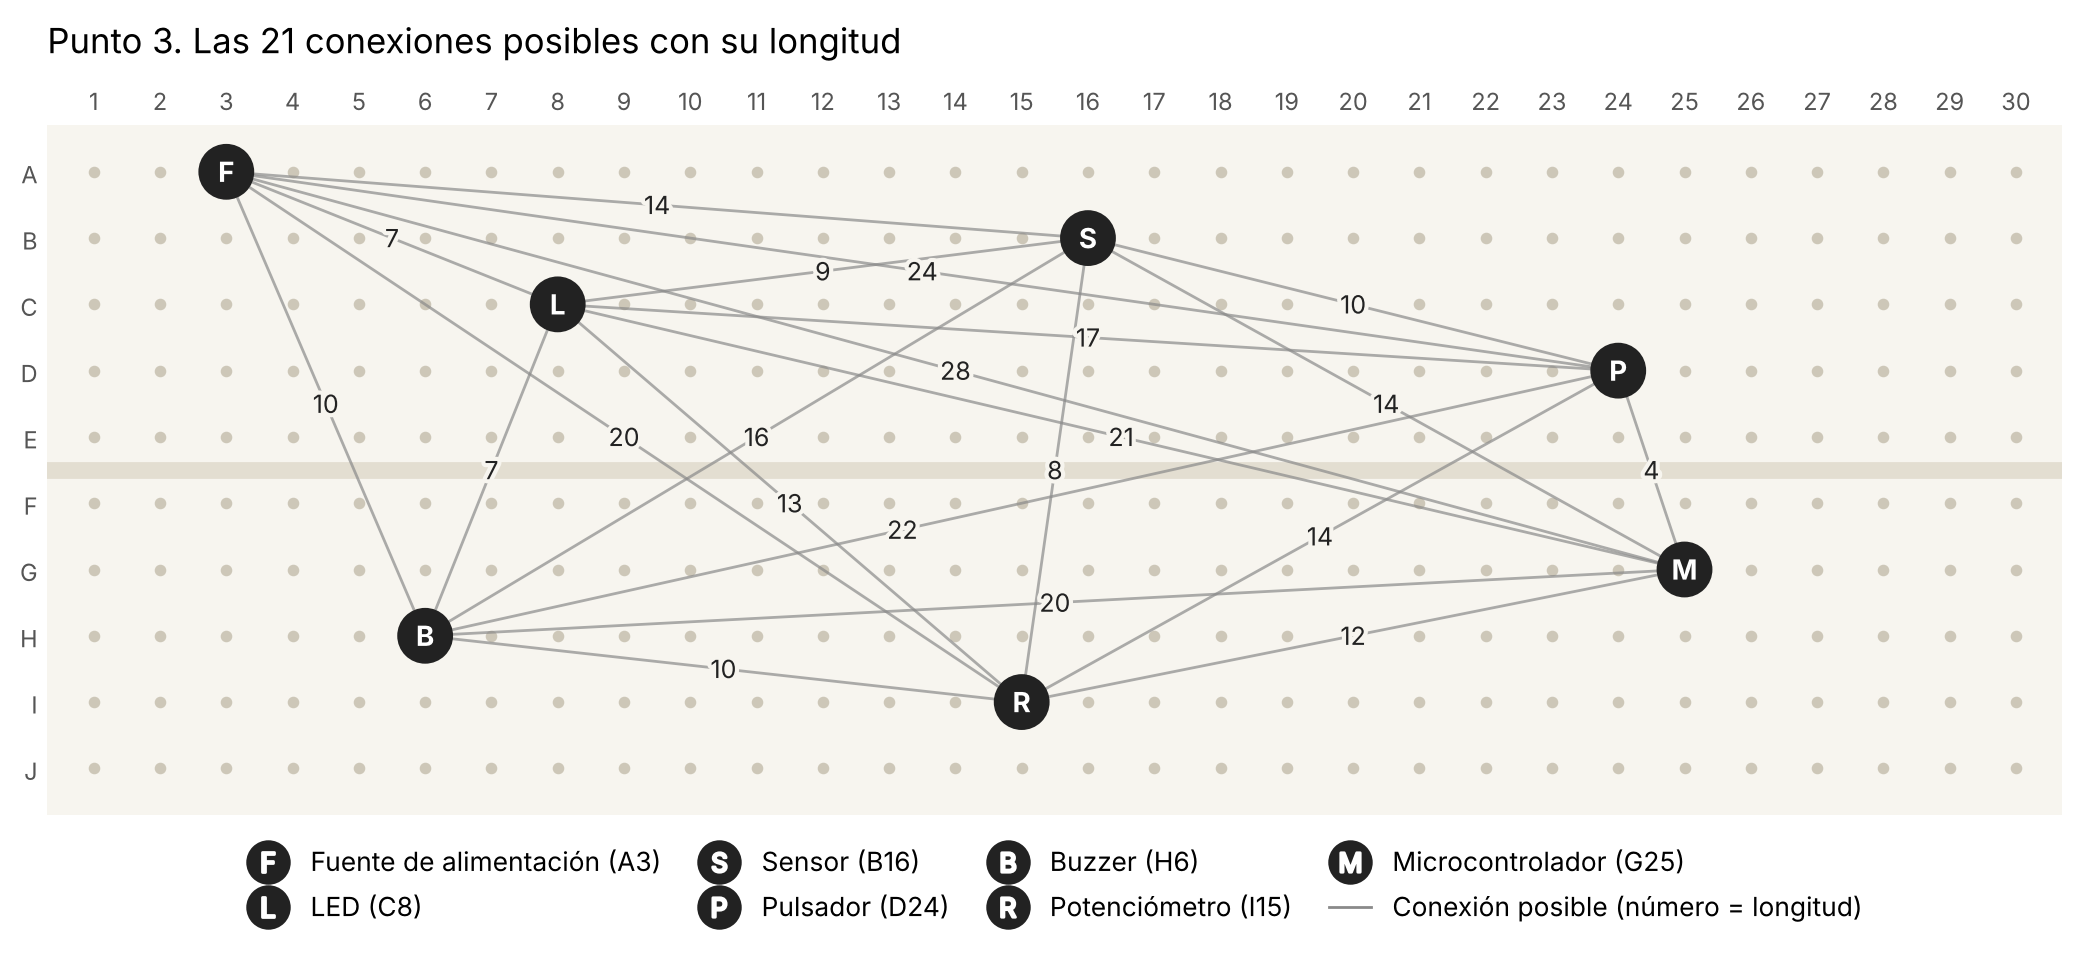

In [10]:
print(f"Conexiones posibles: n(n - 1)/2 = {len(vertices)}·{len(vertices) - 1}/2 = {len(aristas)}")
print(f"Si se pusieran todas, harían falta {longitud(aristas)} unidades de cable")

fig, ax = plt.subplots(figsize=(13, 5.4))
dibujar_protoboard(ax, POSICIONES, f"Punto 3. Las {len(aristas)} conexiones posibles con su longitud",
                   todas=aristas)
leyenda(ax, POSICIONES, [(Line2D([], [], color=GRIS, lw=1), "Conexión posible (número = longitud)")])
plt.show()

### Punto 4. Árbol de Expansión Mínima con Kruskal
Se ordenan las conexiones y se recorre la lista: cada arista entra si une dos grupos distintos y se rechaza si sus extremos ya están en el mismo grupo.

In [11]:
arbol, traza = kruskal(vertices, aristas)

print("Conexiones ordenadas de menor a mayor peso:")
ordenadas = ordenar(aristas)
for i in range(0, len(ordenadas), 7):
    print("   ".join(f"{u}-{v} {peso:>2}" for peso, u, v in ordenadas[i:i + 7]))

print("\nRecorrido de Kruskal:")
mostrar_traza(vertices, traza)

rechazadas = [paso for paso in traza if not paso[3]]
print(f"\nSe revisaron {len(traza)} de {len(aristas)} conexiones: "
      f"{len(arbol)} aceptadas y {len(rechazadas)} rechazadas por formar ciclo.")
print(f"Con {len(arbol)} cables ya quedan conectados los {len(vertices)} componentes, "
      f"así que las otras {len(aristas) - len(traza)} conexiones no se revisan.")

Conexiones ordenadas de menor a mayor peso:
P-M  4   F-L  7   L-B  7   S-R  8   L-S  9   B-R 10   F-B 10
S-P 10   R-M 12   L-R 13   F-S 14   P-R 14   S-M 14   S-B 16
L-P 17   B-M 20   F-R 20   L-M 21   P-B 22   F-P 24   F-M 28

Recorrido de Kruskal:
Paso  Cable   Peso   Decisión    Detalle
01    P - M      4   aceptada    une {P} con {M}
02    F - L      7   aceptada    une {F} con {L}
03    L - B      7   aceptada    une {F, L} con {B}
04    S - R      8   aceptada    une {S} con {R}
05    L - S      9   aceptada    une {B, F, L} con {R, S}
06    B - R     10   rechazada   B y R ya están en {B, F, L, R, S}: formaría un ciclo
07    F - B     10   rechazada   F y B ya están en {B, F, L, R, S}: formaría un ciclo
08    S - P     10   aceptada    une {B, F, L, R, S} con {M, P}

Se revisaron 8 de 21 conexiones: 6 aceptadas y 2 rechazadas por formar ciclo.
Con 6 cables ya quedan conectados los 7 componentes, así que las otras 13 conexiones no se revisan.


### Punto 5. Visualización del resultado
Se imprime el resultado con el formato pedido, se verifica que el árbol tenga n - 1 cables y que conecte todo, y se compara con otros árboles de 6 cables. La figura muestra arriba la distribución original y abajo únicamente los 6 cables elegidos por Kruskal, como pide el enunciado, para comparar las dos.

========== RESULTADO ==========
Cable 1: P - M = 4
Cable 2: F - L = 7
Cable 3: L - B = 7
Cable 4: S - R = 8
Cable 5: L - S = 9
Cable 6: S - P = 10
Longitud total de cable: 45 unidades

len(arbol)=6   len(vertices) - 1=6
¿Conecta los 7 componentes? True

Otros árboles de 6 cables también conectan todo, pero usan más cable:
  Todo directo a la fuente F   103 unidades   (+58)
  En cadena F-L-S-P-B-R-M       70 unidades   (+25)
  MST con Kruskal               45 unidades   (+0)


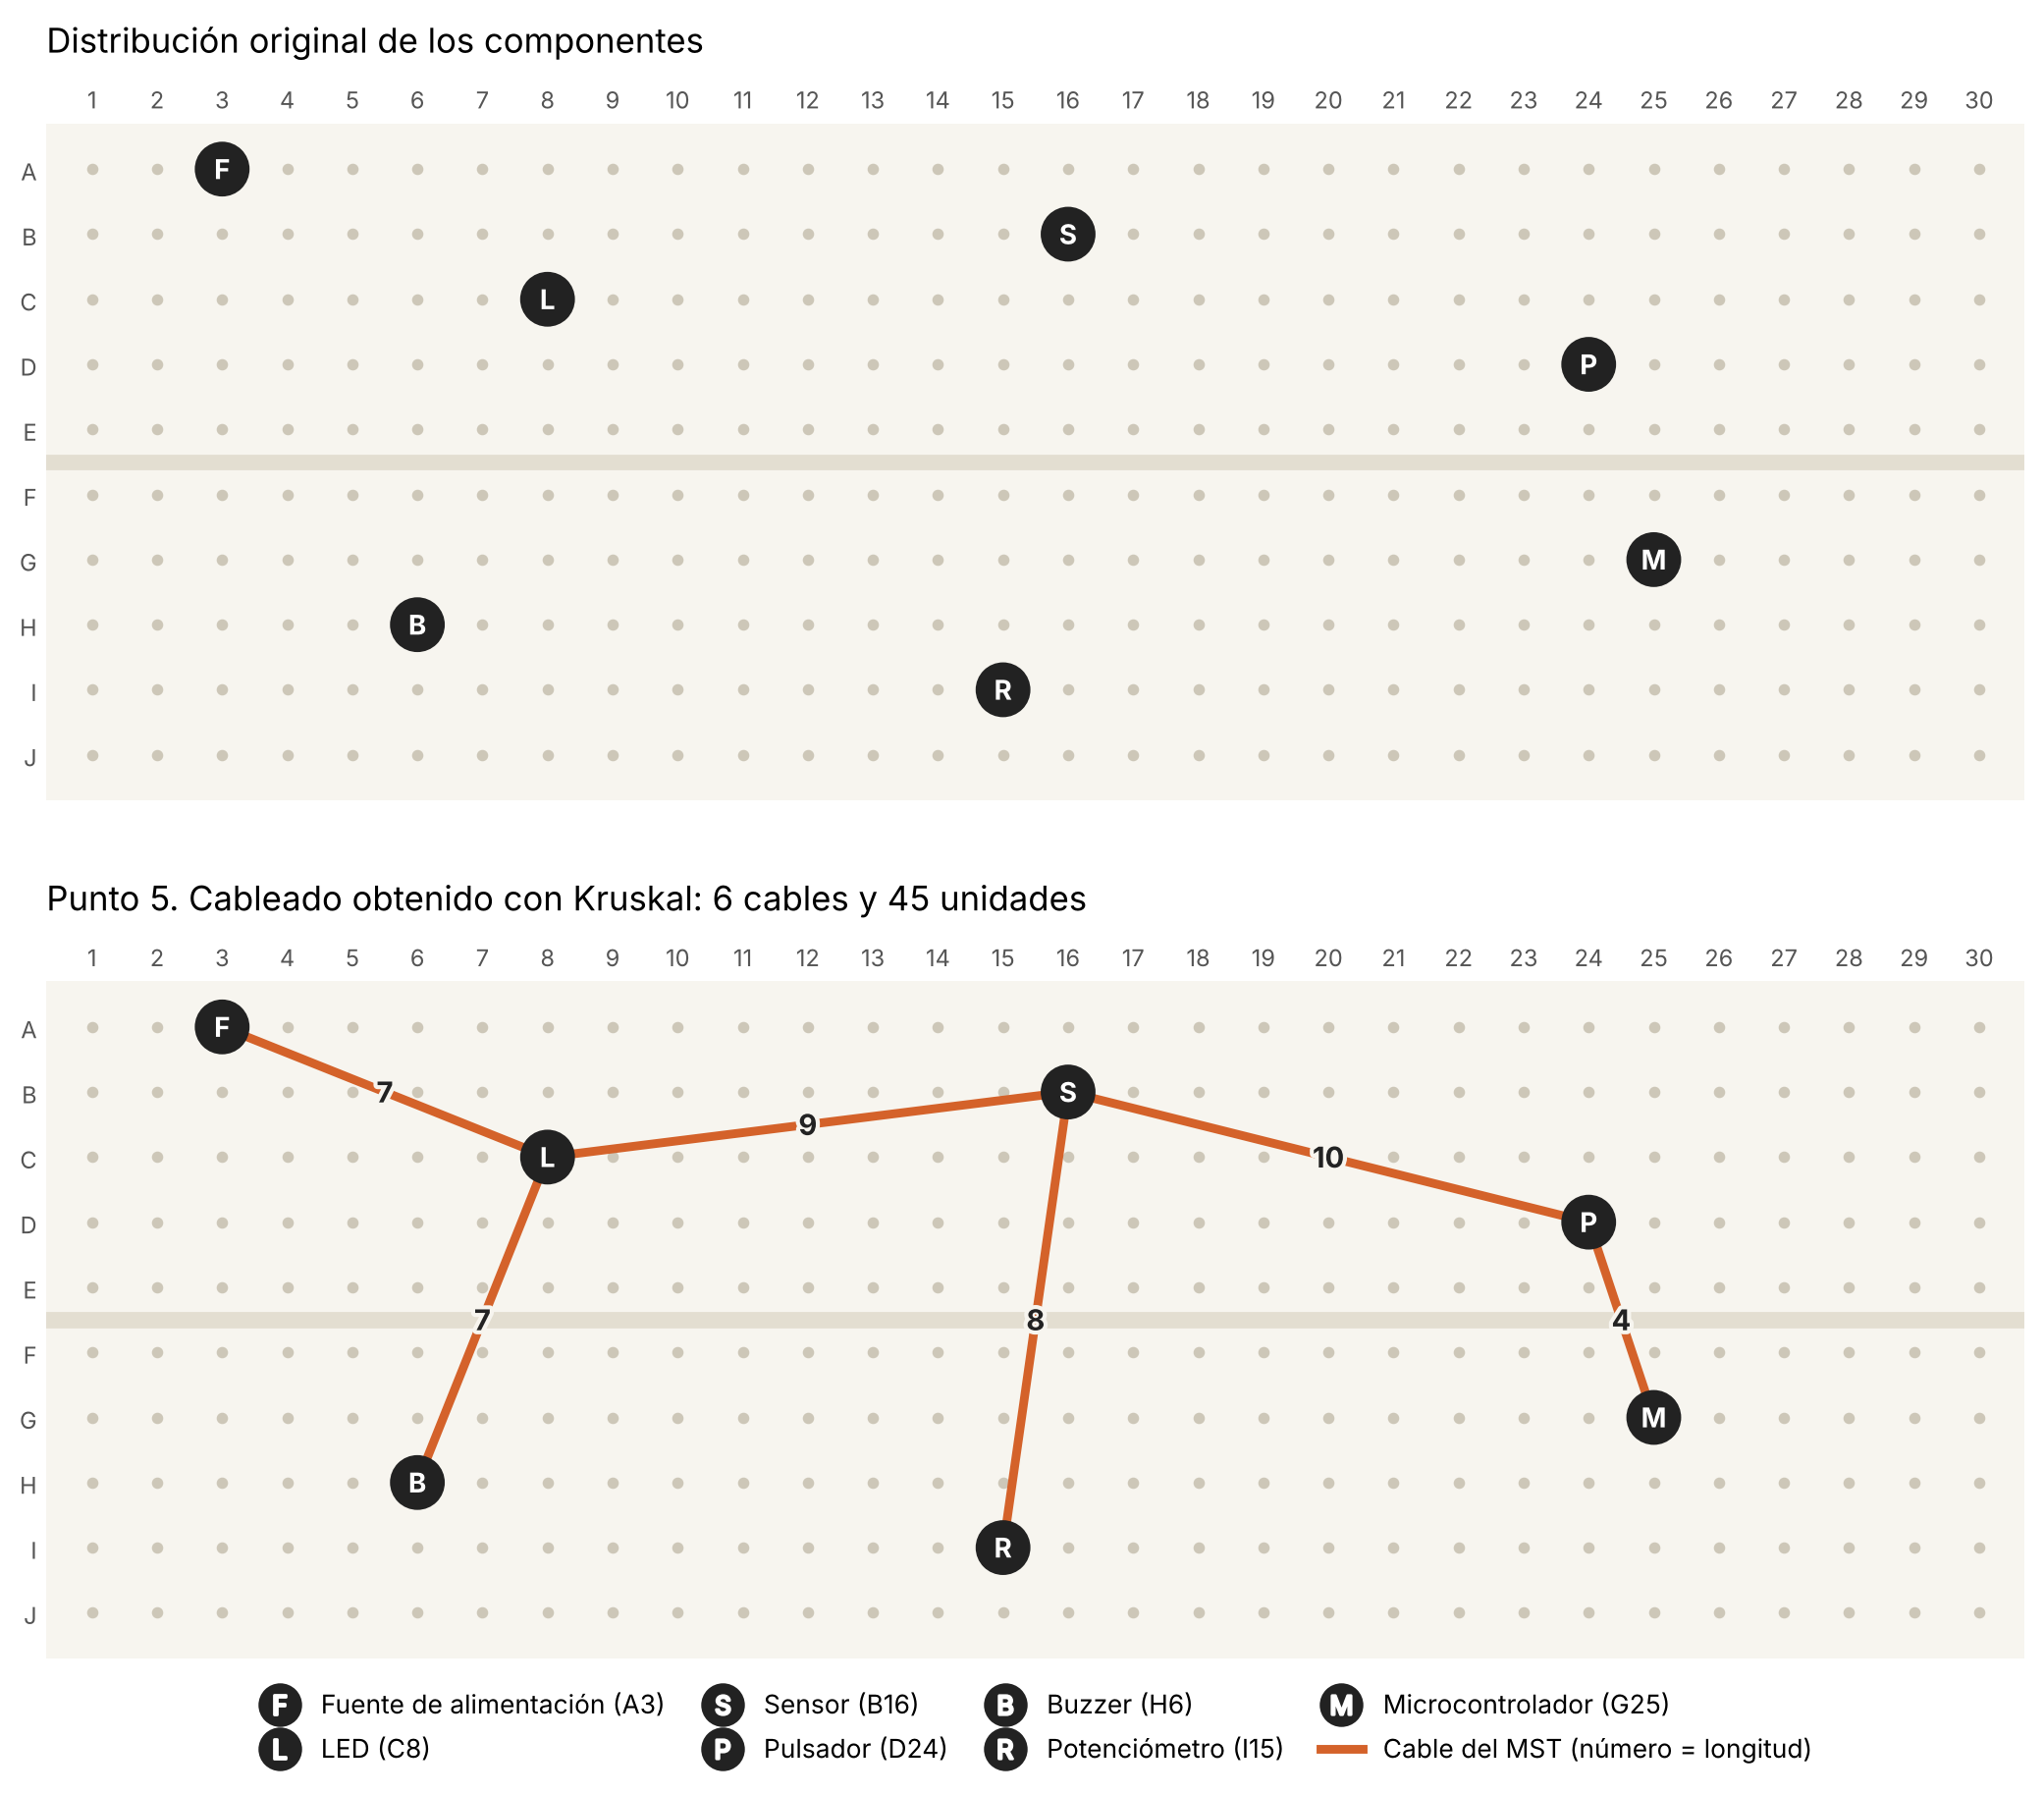

In [12]:
mostrar_resultado(arbol)

print(f"\n{len(arbol)=}   {len(vertices) - 1=}")
print(f"¿Conecta los {len(vertices)} componentes? {conecta_todos(vertices, arbol)}")

estrella = [a for a in aristas if "F" in (a[1], a[2])]
cadena = [(distancia(POSICIONES[u], POSICIONES[v]), u, v) for u, v in zip(vertices, vertices[1:])]
otros = [
    ("Todo directo a la fuente F", estrella),
    ("En cadena F-L-S-P-B-R-M", cadena),
    ("MST con Kruskal", arbol),
]
print("\nOtros árboles de 6 cables también conectan todo, pero usan más cable:")
for nombre, otro in otros:
    print(f"  {nombre:<28}{longitud(otro):>4} unidades   ({longitud(otro) - longitud(arbol):+d})")

titulo = f"Punto 5. Cableado obtenido con Kruskal: {len(arbol)} cables y {longitud(arbol)} unidades"
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10.4))
dibujar_protoboard(ax1, POSICIONES, "Distribución original de los componentes")
dibujar_protoboard(ax2, POSICIONES, titulo, mst=arbol)
leyenda(ax2, POSICIONES, [(Line2D([], [], color=CABLE, lw=3.2), "Cable del MST (número = longitud)")])
plt.show()

### Punto 6. Cambio en la distribución
El Buzzer pasa de H6 a J20 con `mover`, que devuelve una copia, y `calcular_mst` reconstruye el grafo y el árbol con la nueva posición.

El Buzzer pasa de H6 a J20. Solo cambian las aristas que tocan a B:
Arista   Antes  Después  Cambio
F - B       10       26     +16
L - B        7       19     +12
S - B       16       12      -4
P - B       22       10     -12
B - R       10        6      -4
B - M       20        8     -12

Recorrido de Kruskal con la nueva posición:
Paso  Cable   Peso   Decisión    Detalle
01    P - M      4   aceptada    une {P} con {M}
02    B - R      6   aceptada    une {B} con {R}
03    F - L      7   aceptada    une {F} con {L}
04    B - M      8   aceptada    une {B, R} con {M, P}
05    S - R      8   aceptada    une {S} con {B, M, P, R}
06    L - S      9   aceptada    une {F, L} con {B, M, P, R, S}

========== RESULTADO ==========
Cable 1: P - M = 4
Cable 2: B - R = 6
Cable 3: F - L = 7
Cable 4: B - M = 8
Cable 5: S - R = 8
Cable 6: L - S = 9
Longitud total de cable: 42 unidades

MST original
Longitud total: 45

MST después del cambio
Longitud total: 42

La cantidad total de cable disminuyó:

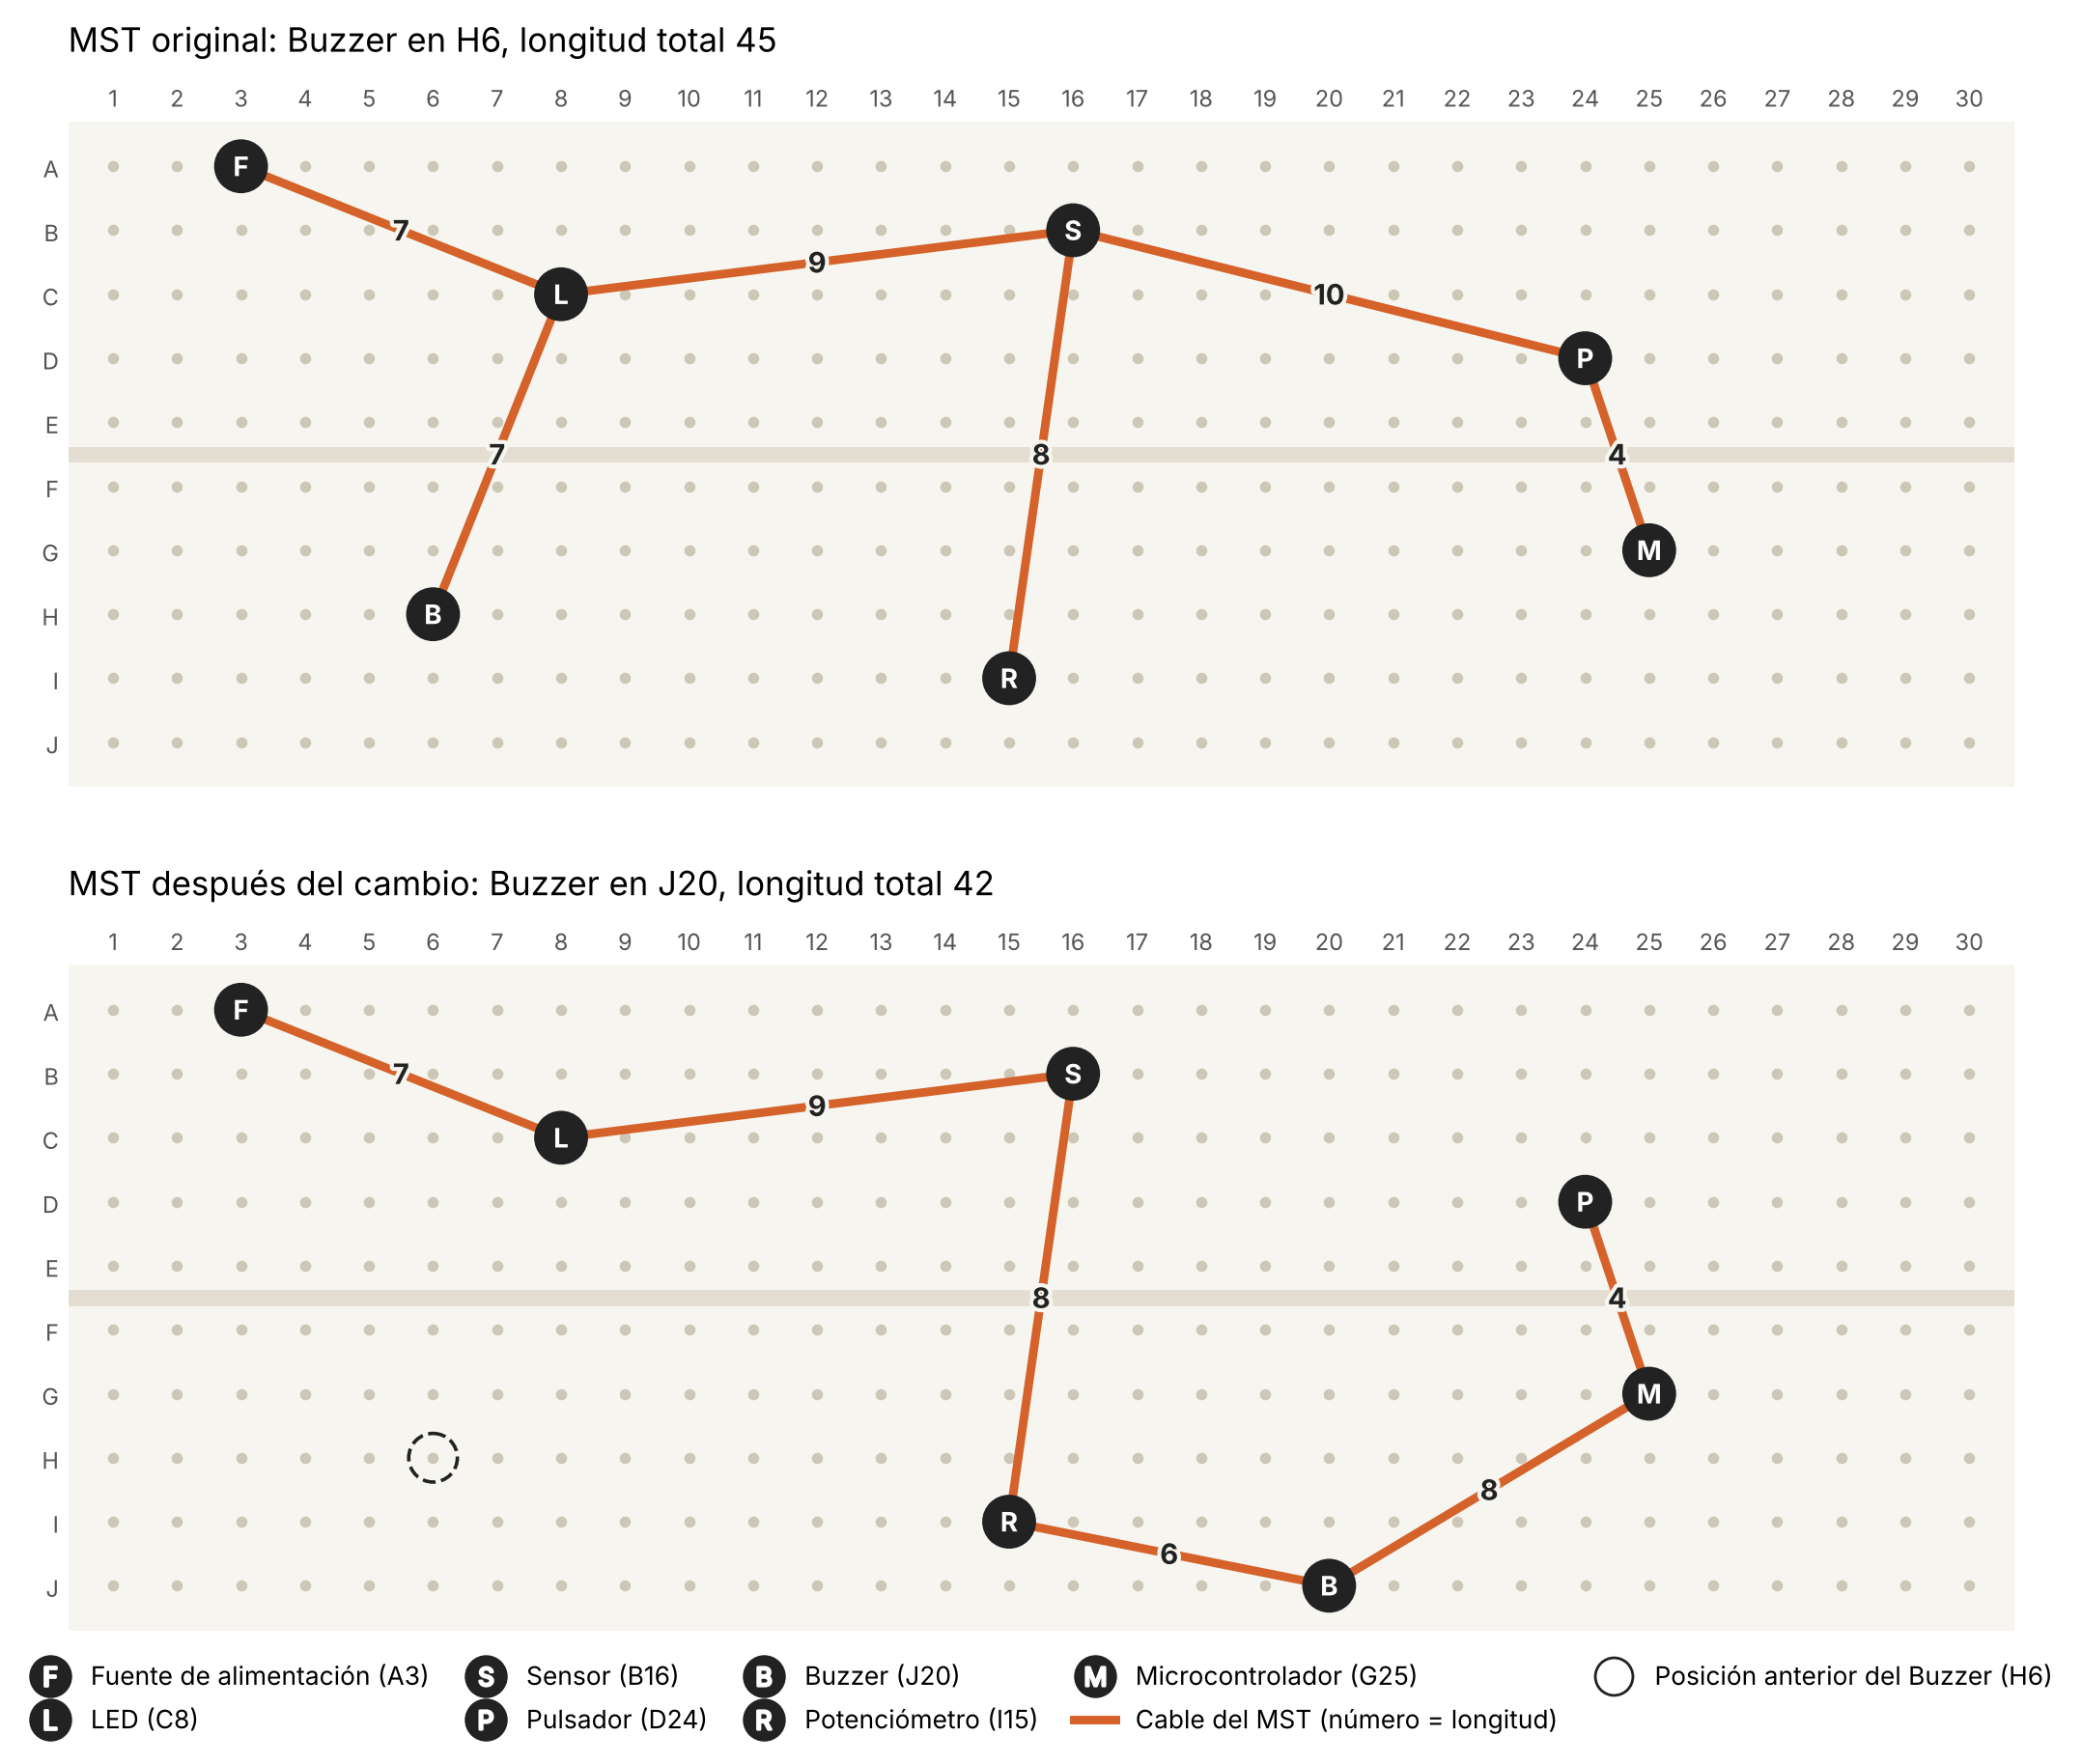

In [13]:
nuevas = mover(POSICIONES, "B", "J20")
assert nuevas is not None, "J20 no existe o ya está ocupada"
print(f"El Buzzer pasa de {POSICIONES['B']} a {nuevas['B']}. Solo cambian las aristas que tocan a B:")
print(f"{'Arista':<8}{'Antes':>6}{'Después':>9}{'Cambio':>8}")
for peso, u, v in aristas:
    if "B" in (u, v):
        ahora = distancia(nuevas[u], nuevas[v])
        print(f"{u + ' - ' + v:<8}{peso:>6}{ahora:>9}{ahora - peso:>+8}")

aristas2, arbol2, traza2 = calcular_mst(nuevas)
print("\nRecorrido de Kruskal con la nueva posición:")
mostrar_traza(vertices, traza2)
print()
mostrar_resultado(arbol2)

original, nuevo = longitud(arbol), longitud(arbol2)
print(f"\nMST original\nLongitud total: {original}\n")
print(f"MST después del cambio\nLongitud total: {nuevo}\n")
if nuevo < original:
    cambio = "disminuyó"
elif nuevo > original:
    cambio = "aumentó"
else:
    cambio = "se mantuvo igual"
diferencia = nuevo - original
print(f"La cantidad total de cable {cambio}: {diferencia:+d} unidades ({diferencia / original:+.1%}).")

antes = {(u, v): peso for peso, u, v in arbol}
despues = {(u, v): peso for peso, u, v in arbol2}
salen = [(peso, u, v) for (u, v), peso in antes.items() if (u, v) not in despues]
entran = [(peso, u, v) for (u, v), peso in despues.items() if (u, v) not in antes]
texto_salen = ", ".join(f"{u} - {v} ({peso})" for peso, u, v in salen)
texto_entran = ", ".join(f"{u} - {v} ({peso})" for peso, u, v in entran)
print(f"Salen:  {texto_salen}  ->  {longitud(salen)} unidades")
print(f"Entran: {texto_entran}  ->  {longitud(entran)} unidades")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10.4))
dibujar_protoboard(ax1, POSICIONES, f"MST original: Buzzer en {POSICIONES['B']}, longitud total {original}",
                   mst=arbol)
dibujar_protoboard(ax2, nuevas, f"MST después del cambio: Buzzer en {nuevas['B']}, longitud total {nuevo}",
                   mst=arbol2, anterior=POSICIONES["B"])
anterior = Line2D([], [], marker="o", ls="", ms=14, mfc="none", mec=TINTA)
leyenda(ax2, nuevas, [(Line2D([], [], color=CABLE, lw=3.2), "Cable del MST (número = longitud)"),
                      (anterior, f"Posición anterior del Buzzer ({POSICIONES['B']})")])
plt.show()

**¿Aumentó o disminuyó la cantidad total de cable?** Disminuyó: pasó de 45 a 42 unidades, 3 menos ($-6{,}7\,\%$). En H6 el Buzzer se conectaba al LED con un cable de 7, y el grupo del Pulsador y el Microcontrolador necesitaba el cable S - P de 10. En J20 el Buzzer queda a 6 del Potenciómetro y a 8 del Microcontrolador, así que sirve de puente: entran B - R (6) y B - M (8), que suman 14, y salen L - B (7) y S - P (10), que suman 17.

### Formatos de f-string usados

| Formato | Qué hace | Dónde se usa | Resultado |
|---|---|---|---|
| `{' RESULTADO ':=^31}` | centra el texto en 31 caracteres y rellena con `=` | `mostrar_resultado` | `========== RESULTADO ==========` |
| `{f' {peso} ':-^19}` | f-string dentro de otro, centrado con relleno de `-` | aristas del Punto 2 | `-------- 7 --------` |
| `{c:>3}`, `{peso:>4}` | alinea a la derecha en un ancho fijo | protoboard en texto, matriz, traza | `  7` |
| `{decision:<12}` | alinea a la izquierda | traza de Kruskal | `aceptada    ` |
| `{comp:^4}` | centra | tabla de posiciones | ` F  ` |
| `{nombre:<{ancho}}` | el ancho sale de una variable | tabla de posiciones | ancho del nombre más largo |
| `{k:02d}` | entero con ceros a la izquierda | número de paso | `01` |
| `{x:+d}`, `{ahora - peso:>+8}` | muestra siempre el signo | Puntos 5 y 6 | `+58`, `-12` |
| `{x:+.1%}` | porcentaje con signo y un decimal | Punto 6 | `-6.7%` |
| `{t * 1e3:>14.2f}` | número con dos decimales | pruebas de desempeño | `126.70` |
| `{E:,}` | separador de miles (después se cambia `,` por `.`) | desempeño y gráfica de complejidad | `44.850` |
| `{pos!r}` | muestra el valor con `repr`, con comillas | mensajes de error y nombres de tests | `'K5'` |
| `{obtenido!s}` | convierte el valor con `str` | función `test` | `True` |
| `{nombre + ' ':.<68}` | rellena con puntos hasta un ancho | función `test` | `Distancia F - L ...... 7` |
| `{len(arbol)=}` | imprime la expresión y su valor | Punto 5 | `len(arbol)=6` |

## 7) Tests aplicados **[15 pts]**

Las pruebas están en cinco grupos: valores del enunciado, casos frontera de posiciones y distancias, casos frontera del grafo y de Kruskal, oráculos y un certificado de optimalidad que comprueban el MST por otros caminos, y desempeño. La función `test` compara el valor obtenido con el esperado y detiene el notebook con un mensaje si no coinciden; cada línea impresa es una prueba que pasó.

In [14]:
import io
import math
import random
import time
from contextlib import redirect_stdout
from itertools import combinations

resultados = []


def test(nombre, obtenido, esperado):
    assert obtenido == esperado, f"{nombre}: se obtuvo {obtenido!r} y se esperaba {esperado!r}"
    resultados.append(nombre)
    print(f"Pasó {len(resultados):>2}. {nombre + ' ':.<68} {obtenido!s}")

### 7.1 Valores del enunciado
Se comprueban las distancias de ejemplo, las 21 aristas, los 6 cables, las longitudes 45 y 42 y que mover el Buzzer no cambie la distribución original. También se captura lo que imprime `mostrar_resultado` para verificar, carácter por carácter, el formato que pide el enunciado, y se revisa que la protoboard en texto ponga cada componente en su perforación.

In [15]:
test("Coordenadas de F en A3", a_coordenadas("A3"), (3, 1))
test("Coordenadas de L en C8", a_coordenadas("C8"), (8, 3))
test("Distancia F - L del enunciado", distancia("A3", "C8"), 7)
test("Distancia L - S del enunciado", distancia("C8", "B16"), 9)
test("Distancia S - P del enunciado", distancia("B16", "D24"), 10)
test("La distribución inicial no tiene errores", validar(POSICIONES), [])
test("Aristas del grafo completo: 7·6/2", len(aristas), 21)
test("Cables del MST: n - 1", len(arbol), 6)
test("Longitud total del MST original", longitud(arbol), 45)
cables = " ".join(f"{u}-{v}" for peso, u, v in arbol)
test("Cables elegidos por Kruskal", cables, "P-M F-L L-B S-R L-S S-P")
test("El MST conecta los 7 componentes", conecta_todos(vertices, arbol), True)
test("Mover B a J20 da una distribución válida", validar(nuevas), [])
test("Mover B no cambia la distribución original", POSICIONES["B"], "H6")
test("Longitud total del MST después del cambio", longitud(arbol2), 42)
cables2 = " ".join(f"{u}-{v}" for peso, u, v in arbol2)
test("Cables del MST después del cambio", cables2, "P-M B-R F-L B-M S-R L-S")
test("Diferencia de cable: disminuye", longitud(arbol2) - longitud(arbol), -3)

salida = io.StringIO()
with redirect_stdout(salida):
    mostrar_resultado(arbol)
esperado = (
    "========== RESULTADO ==========\n"
    "Cable 1: P - M = 4\n"
    "Cable 2: F - L = 7\n"
    "Cable 3: L - B = 7\n"
    "Cable 4: S - R = 8\n"
    "Cable 5: L - S = 9\n"
    "Cable 6: S - P = 10\n"
    "Longitud total de cable: 45 unidades\n"
)
test("Formato exacto del bloque RESULTADO", salida.getvalue() == esperado, True)
lineas = protoboard_texto(POSICIONES).splitlines()
test("Protoboard en texto: F en la fila A, columna 3", lineas[1].split()[3], "F")
test("Protoboard en texto: B en la fila H, columna 6", lineas[8].split()[6], "B")
test("Protoboard en texto: perforaciones libres (300 - 7)", sum(linea.count("·") for linea in lineas), 293)

Pasó  1. Coordenadas de F en A3 ............................................. (3, 1)
Pasó  2. Coordenadas de L en C8 ............................................. (8, 3)
Pasó  3. Distancia F - L del enunciado ...................................... 7
Pasó  4. Distancia L - S del enunciado ...................................... 9
Pasó  5. Distancia S - P del enunciado ...................................... 10
Pasó  6. La distribución inicial no tiene errores ........................... []
Pasó  7. Aristas del grafo completo: 7·6/2 .................................. 21
Pasó  8. Cables del MST: n - 1 .............................................. 6
Pasó  9. Longitud total del MST original .................................... 45
Pasó 10. Cables elegidos por Kruskal ........................................ P-M F-L L-B S-R L-S S-P
Pasó 11. El MST conecta los 7 componentes ................................... True
Pasó 12. Mover B a J20 da una distribución válida ........................... []


### 7.2 Casos frontera: posiciones y distancias
Se prueban las cuatro esquinas válidas y entradas inválidas que podrían colarse: fila K, columnas 0 y 31, cero a la izquierda, texto vacío o incompleto, letra minúscula, signos, decimales, espacios, el superíndice `³` (que `isdigit()` acepta pero `int()` no convierte) y valores que no son texto. También se revisan las distancias extremas (38 es la máxima) y, sobre las 300 perforaciones, la simetría, el cero y la desigualdad triangular.

In [16]:
casos = [
    ("A1", True), ("J30", True), ("A30", True), ("J1", True),
    ("K5", False), ("A0", False), ("A31", False), ("A03", False),
    ("", False), ("A", False), ("3A", False), ("a3", False),
    ("A-1", False), ("A3.5", False), ("A 3", False), ("A³", False),
    (None, False), (35, False),
]
for entrada, esperado in casos:
    test(f"posicion_valida({entrada!r})", posicion_valida(entrada), esperado)

test("Esquinas opuestas A1 y J30: distancia máxima", distancia("A1", "J30"), 38)
test("Misma fila: A1 y A30", distancia("A1", "A30"), 29)
test("Misma columna: A5 y J5", distancia("A5", "J5"), 9)
test("Vecinas a lado y lado del canal central: E10 y F10", distancia("E10", "F10"), 1)
test("Misma perforación: C7 y C7", distancia("C7", "C7"), 0)

huecos = [f"{f}{c}" for f in FILAS for c in range(1, COLUMNAS + 1)]
parejas = [(p, q) for p in huecos for q in huecos]
simetrica = all(distancia(p, q) == distancia(q, p) for p, q in parejas)
cero = all((distancia(p, q) == 0) == (p == q) for p, q in parejas)
test("Perforaciones de la protoboard", len(huecos), 300)
test("Simetría d(p, q) = d(q, p) en las 90.000 parejas", simetrica, True)
test("d(p, q) = 0 solo cuando p = q", cero, True)
test("Distancia máxima entre todas las parejas", max(distancia(p, q) for p, q in parejas), 38)

random.seed(1)
trios = [random.sample(huecos, 3) for _ in range(5000)]
triangular = all(distancia(p, r) <= distancia(p, q) + distancia(q, r) for p, q, r in trios)
test("Desigualdad triangular en 5.000 tríos aleatorios", triangular, True)

test("Dos componentes en la misma perforación se reportan", validar({"F": "A3", "L": "A3"}),
     ["L: la posición A3 ya la ocupa F"])
test("Una posición fuera de la protoboard se reporta", len(validar({"F": "K3", "L": "C8"})), 1)

Pasó 21. posicion_valida('A1') .............................................. True
Pasó 22. posicion_valida('J30') ............................................. True
Pasó 23. posicion_valida('A30') ............................................. True
Pasó 24. posicion_valida('J1') .............................................. True
Pasó 25. posicion_valida('K5') .............................................. False
Pasó 26. posicion_valida('A0') .............................................. False
Pasó 27. posicion_valida('A31') ............................................. False
Pasó 28. posicion_valida('A03') ............................................. False
Pasó 29. posicion_valida('') ................................................ False
Pasó 30. posicion_valida('A') ............................................... False
Pasó 31. posicion_valida('3A') .............................................. False
Pasó 32. posicion_valida('a3') .............................................. Fa

### 7.3 Casos frontera: grafo, Kruskal y conjuntos disjuntos
Kruskal se prueba con 0, 1 y 2 componentes, una fila completa, la protoboard llena (300 componentes y 44.850 aristas), empates de peso, un triángulo de lados iguales donde una arista debe rechazarse por ciclo, aristas raras (un lazo y dos aristas entre la misma pareja) y un grafo desconectado, donde no existe árbol de expansión. En los conjuntos disjuntos se revisa la detección de ciclos, la compresión de caminos y que el rango no pase de $\log_2 n$. También se compara `ordenar` con `sorted()` y se prueban los casos en que `mover` debe rechazar el cambio.

In [17]:
test("n = 0: grafo sin aristas", construir_grafo({}), [])
test("n = 0: Kruskal sin cables", kruskal([], []), ([], []))
test("n = 1: un componente no necesita cables", calcular_mst({"X": "E15"})[1], [])
test("n = 2: un solo cable de A1 a J30", calcular_mst({"X": "A1", "Y": "J30"})[1], [(38, "X", "Y")])

fila = {f"C{c}": f"A{c}" for c in range(1, COLUMNAS + 1)}
arbol_fila = calcular_mst(fila)[1]
test("30 componentes en la fila A: cables y longitud", (len(arbol_fila), longitud(arbol_fila)), (29, 29))

llena = {f"C{i}": h for i, h in enumerate(huecos)}
aristas_llena, arbol_llena, traza_llena = calcular_mst(llena)
test("Protoboard llena (300 componentes): aristas del grafo", len(aristas_llena), 44850)
test("Protoboard llena: 299 cables, todos de longitud 1", (len(arbol_llena), longitud(arbol_llena)), (299, 299))
test("Protoboard llena: el árbol conecta todo", conecta_todos(list(llena), arbol_llena), True)

cuadrado = {"W": "A1", "X": "A3", "Y": "C1", "Z": "C3"}
test("Cuadrado con los cuatro lados iguales (empates)", longitud(calcular_mst(cuadrado)[1]), 6)

triangulo = {"X": "A1", "Y": "A3", "Z": "B2", "W": "J30"}
arbol_t, traza_t = calcular_mst(triangulo)[1:]
rechazadas_t = [paso for paso in traza_t if not paso[3]]
test("Triángulo de lados iguales: aristas rechazadas por ciclo", len(rechazadas_t), 1)
test("Triángulo de lados iguales y un componente lejano: total", longitud(arbol_t), 40)

lazo = kruskal(["X", "Y"], [(0, "X", "X"), (5, "X", "Y")])[0]
test("Arista de un componente consigo mismo: se rechaza", lazo, [(5, "X", "Y")])
repetida = kruskal(["X", "Y"], [(5, "X", "Y"), (3, "X", "Y")])[0]
test("Dos aristas entre la misma pareja: queda la más corta", repetida, [(3, "X", "Y")])
bosque = kruskal(["W", "X", "Y", "Z"], [(1, "W", "X"), (2, "Y", "Z")])[0]
test("Grafo desconectado: Kruskal solo logra 2 cables", len(bosque), 2)
test("Grafo desconectado: el resultado no conecta todo", conecta_todos(["W", "X", "Y", "Z"], bosque), False)

padre, rango = crear_conjuntos(["A", "B", "C", "D"])
test("unir A y B la primera vez", unir(padre, rango, "A", "B"), True)
test("unir A y B otra vez: ya están juntos, sería ciclo", unir(padre, rango, "A", "B"), False)
unir(padre, rango, "C", "D")
unir(padre, rango, "B", "D")
test("Antes de buscar, D apunta a C (camino D -> C -> A)", padre["D"], "C")
test("encontrar(D) devuelve la raíz A", encontrar(padre, "D"), "A")
test("Compresión de caminos: ahora D apunta directo a A", padre["D"], "A")

random.seed(4)
elementos = list(range(300))
padre, rango = crear_conjuntos(elementos)
for _ in range(2000):
    unir(padre, rango, random.choice(elementos), random.choice(elementos))
test("Unión por rango: rango máximo <= log2(300) = 8,2", max(rango.values()) <= math.log2(300), True)

test("ordenar una lista vacía", ordenar([]), [])
test("ordenar un solo elemento", ordenar([(5, "X", "Y")]), [(5, "X", "Y")])
test("Pesos empatados: desempata por letras", ordenar([(7, "L", "B"), (7, "F", "L")]),
     [(7, "F", "L"), (7, "L", "B")])
test("Lista al revés", ordenar([(3, "X", "Y"), (2, "X", "Y"), (1, "X", "Y")]),
     [(1, "X", "Y"), (2, "X", "Y"), (3, "X", "Y")])
random.seed(3)
listas = []
for _ in range(200):
    tam = random.randint(0, 60)
    lista = [(random.randint(0, 38), random.choice(FILAS), random.choice(FILAS)) for _ in range(tam)]
    listas.append(lista)
test("ordenar coincide con sorted() en 200 listas aleatorias", all(ordenar(x) == sorted(x) for x in listas), True)
copia = list(aristas)
ordenar(aristas)
test("ordenar no modifica la lista original", aristas == copia, True)

test("Mover a una fila que no existe (K20)", mover(POSICIONES, "B", "K20"), None)
test("Mover a una columna que no existe (J31)", mover(POSICIONES, "B", "J31"), None)
test("Mover a una perforación ocupada por F (A3)", mover(POSICIONES, "B", "A3"), None)
test("Mover un componente que no existe (X)", mover(POSICIONES, "X", "J20"), None)
igual = mover(POSICIONES, "B", "H6")
test("Mover B a su misma posición deja el total en 45", longitud(calcular_mst(igual)[1]), 45)

Pasó 51. n = 0: grafo sin aristas ........................................... []
Pasó 52. n = 0: Kruskal sin cables .......................................... ([], [])
Pasó 53. n = 1: un componente no necesita cables ............................ []
Pasó 54. n = 2: un solo cable de A1 a J30 ................................... [(38, 'X', 'Y')]
Pasó 55. 30 componentes en la fila A: cables y longitud ..................... (29, 29)


Pasó 56. Protoboard llena (300 componentes): aristas del grafo .............. 44850
Pasó 57. Protoboard llena: 299 cables, todos de longitud 1 .................. (299, 299)
Pasó 58. Protoboard llena: el árbol conecta todo ............................ True
Pasó 59. Cuadrado con los cuatro lados iguales (empates) .................... 6
Pasó 60. Triángulo de lados iguales: aristas rechazadas por ciclo ........... 1
Pasó 61. Triángulo de lados iguales y un componente lejano: total ........... 40
Pasó 62. Arista de un componente consigo mismo: se rechaza .................. [(5, 'X', 'Y')]
Pasó 63. Dos aristas entre la misma pareja: queda la más corta .............. [(3, 'X', 'Y')]
Pasó 64. Grafo desconectado: Kruskal solo logra 2 cables .................... 2
Pasó 65. Grafo desconectado: el resultado no conecta todo ................... False
Pasó 66. unir A y B la primera vez .......................................... True
Pasó 67. unir A y B otra vez: ya están juntos, sería ciclo .........

### 7.4 Oráculos y certificado de optimalidad
Un oráculo calcula la respuesta por otro camino. La fuerza bruta revisa los 54.264 grupos de 6 cables, se queda con los que son árboles y toma el más corto; Prim es otro algoritmo que debe dar el mismo total. Después se repite la comparación en 400 distribuciones aleatorias.

Además se verifica la **propiedad del ciclo**, que certifica que un árbol de expansión es mínimo sin compararlo con nadie: para cada arista $\{u, v\}$ que quedó fuera del árbol, ningún cable del camino entre u y v dentro del árbol puede pesar más que ella. Como control, se cambia el cable S - P (10) por L - P (17): el resultado sigue siendo un árbol de expansión, de 52 unidades, pero ya no cumple la propiedad, que es justo lo que debe detectar el certificado.

In [18]:
def pesos_de_arboles(posiciones):
    vertices = list(posiciones)
    aristas = construir_grafo(posiciones)
    grupos = combinations(aristas, len(vertices) - 1)
    return [longitud(g) for g in grupos if conecta_todos(vertices, g)]


def prim(posiciones):
    comps = list(posiciones)
    mejor = {c: distancia(posiciones[comps[0]], posiciones[c]) for c in comps[1:]}
    total = 0
    while mejor:
        c = min(mejor, key=mejor.get)
        total += mejor.pop(c)
        for d in mejor:
            mejor[d] = min(mejor[d], distancia(posiciones[c], posiciones[d]))
    return total


def distribucion_aleatoria(n):
    lugares = random.sample(huecos, n)
    return {f"C{i}": lugares[i] for i in range(n)}


def mayor_en_camino(arbol, u, v):
    vecinos = {}
    for peso, a, b in arbol:
        vecinos.setdefault(a, []).append((b, peso))
        vecinos.setdefault(b, []).append((a, peso))
    pila = [(u, 0)]
    vistos = {u}
    while pila:
        x, mayor = pila.pop()
        if x == v:
            return mayor
        for y, peso in vecinos[x]:
            if y not in vistos:
                vistos.add(y)
                pila.append((y, max(mayor, peso)))
    return None


def cumple_ciclo(aristas, arbol):
    fuera = [a for a in aristas if a not in arbol]
    return all(mayor_en_camino(arbol, u, v) <= peso for peso, u, v in fuera)


pesos = pesos_de_arboles(POSICIONES)
test("Grupos de 6 cables que se pueden armar con 21 aristas", math.comb(21, 6), 54264)
test("Árboles de expansión del grafo (Cayley: 7^5)", len(pesos), 7 ** 5)
test("Mínimo por fuerza bruta = Kruskal (original)", min(pesos), longitud(arbol))
test("Árboles que logran ese mínimo (el MST es único)", pesos.count(min(pesos)), 1)
promedio = sum(pesos) / len(pesos)
print(f"\nLos {len(pesos)} árboles posibles miden entre {min(pesos)} y {max(pesos)} unidades;", end=" ")
print(f"el promedio es {promedio:.1f}.\n")

pesos2 = pesos_de_arboles(nuevas)
test("Mínimo por fuerza bruta = Kruskal (después del cambio)", min(pesos2), longitud(arbol2))
test("Árboles que logran el mínimo después del cambio", pesos2.count(min(pesos2)), 1)
test("Propiedad del ciclo en el MST original (15 aristas fuera)", cumple_ciclo(aristas, arbol), True)
test("Propiedad del ciclo en el MST después del cambio", cumple_ciclo(aristas2, arbol2), True)
peor_arbol = [a for a in arbol if a != (10, "S", "P")] + [(17, "L", "P")]
control = (longitud(peor_arbol), conecta_todos(vertices, peor_arbol))
test("Control: cambiar S-P por L-P da otro árbol de expansión, de 52", control, (52, True))
test("Control: ese árbol no cumple la propiedad del ciclo", cumple_ciclo(aristas, peor_arbol), False)
test("Prim da el mismo total (original)", prim(POSICIONES), 45)
test("Prim da el mismo total (después del cambio)", prim(nuevas), 42)

random.seed(11)
bien = 0
for _ in range(200):
    posiciones = distribucion_aleatoria(random.randint(2, 6))
    total = longitud(calcular_mst(posiciones)[1])
    if total == min(pesos_de_arboles(posiciones)) == prim(posiciones):
        bien += 1
test("200 distribuciones con n de 2 a 6: Kruskal = fuerza bruta = Prim", bien, 200)

bien = 0
for _ in range(200):
    posiciones = distribucion_aleatoria(random.randint(7, 60))
    arbol_k = calcular_mst(posiciones)[1]
    es_arbol = len(arbol_k) == len(posiciones) - 1 and conecta_todos(list(posiciones), arbol_k)
    if longitud(arbol_k) == prim(posiciones) and es_arbol:
        bien += 1
test("200 distribuciones con n de 7 a 60: Kruskal = Prim y es árbol", bien, 200)

Pasó 83. Grupos de 6 cables que se pueden armar con 21 aristas .............. 54264
Pasó 84. Árboles de expansión del grafo (Cayley: 7^5) ....................... 16807
Pasó 85. Mínimo por fuerza bruta = Kruskal (original) ....................... 45
Pasó 86. Árboles que logran ese mínimo (el MST es único) .................... 1

Los 16807 árboles posibles miden entre 45 y 131 unidades; el promedio es 85.7.



Pasó 87. Mínimo por fuerza bruta = Kruskal (después del cambio) ............. 42
Pasó 88. Árboles que logran el mínimo después del cambio .................... 1
Pasó 89. Propiedad del ciclo en el MST original (15 aristas fuera) .......... True
Pasó 90. Propiedad del ciclo en el MST después del cambio ................... True
Pasó 91. Control: cambiar S-P por L-P da otro árbol de expansión, de 52 ..... (52, True)
Pasó 92. Control: ese árbol no cumple la propiedad del ciclo ................ False
Pasó 93. Prim da el mismo total (original) .................................. 45
Pasó 94. Prim da el mismo total (después del cambio) ........................ 42


Pasó 95. 200 distribuciones con n de 2 a 6: Kruskal = fuerza bruta = Prim ... 200


Pasó 96. 200 distribuciones con n de 7 a 60: Kruskal = Prim y es árbol ...... 200


### 7.5 Pruebas de desempeño
Se mide el tiempo de `calcular_mst` (el mejor de 5 repeticiones) con 10 a 300 componentes en posiciones aleatorias, y se cuenta cuántas aristas revisa el ciclo de Kruskal en el mejor caso (componentes en una fila) y en el peor (un bloque en una esquina y un componente lejano en J30).

    n        E   tiempo (ms)   ns por E·log2(E)
   10       45          0.08              307.0
   25      300          0.53              215.0
   50    1.225          2.47              196.7
  100    4.950         11.54              189.9


  150   11.175         29.39              195.6


  200   19.900         56.13              197.5


  250   31.125         84.59              182.1


  300   44.850        126.36              182.3

Desde n = 50 el cociente queda entre 182.1 y 197.5 ns.
De n = 150 a n = 300 el tiempo se multiplicó por 4.30; n² log n predice 4.61 y n² daría 4.
Caso del laboratorio (n = 7, E = 21): 29.2 µs

Pasó 97. Mejor caso: Kruskal revisa exactamente n - 1 aristas ............... True
Pasó 98. Peor caso: revisa todas las aristas del bloque y una más ........... True


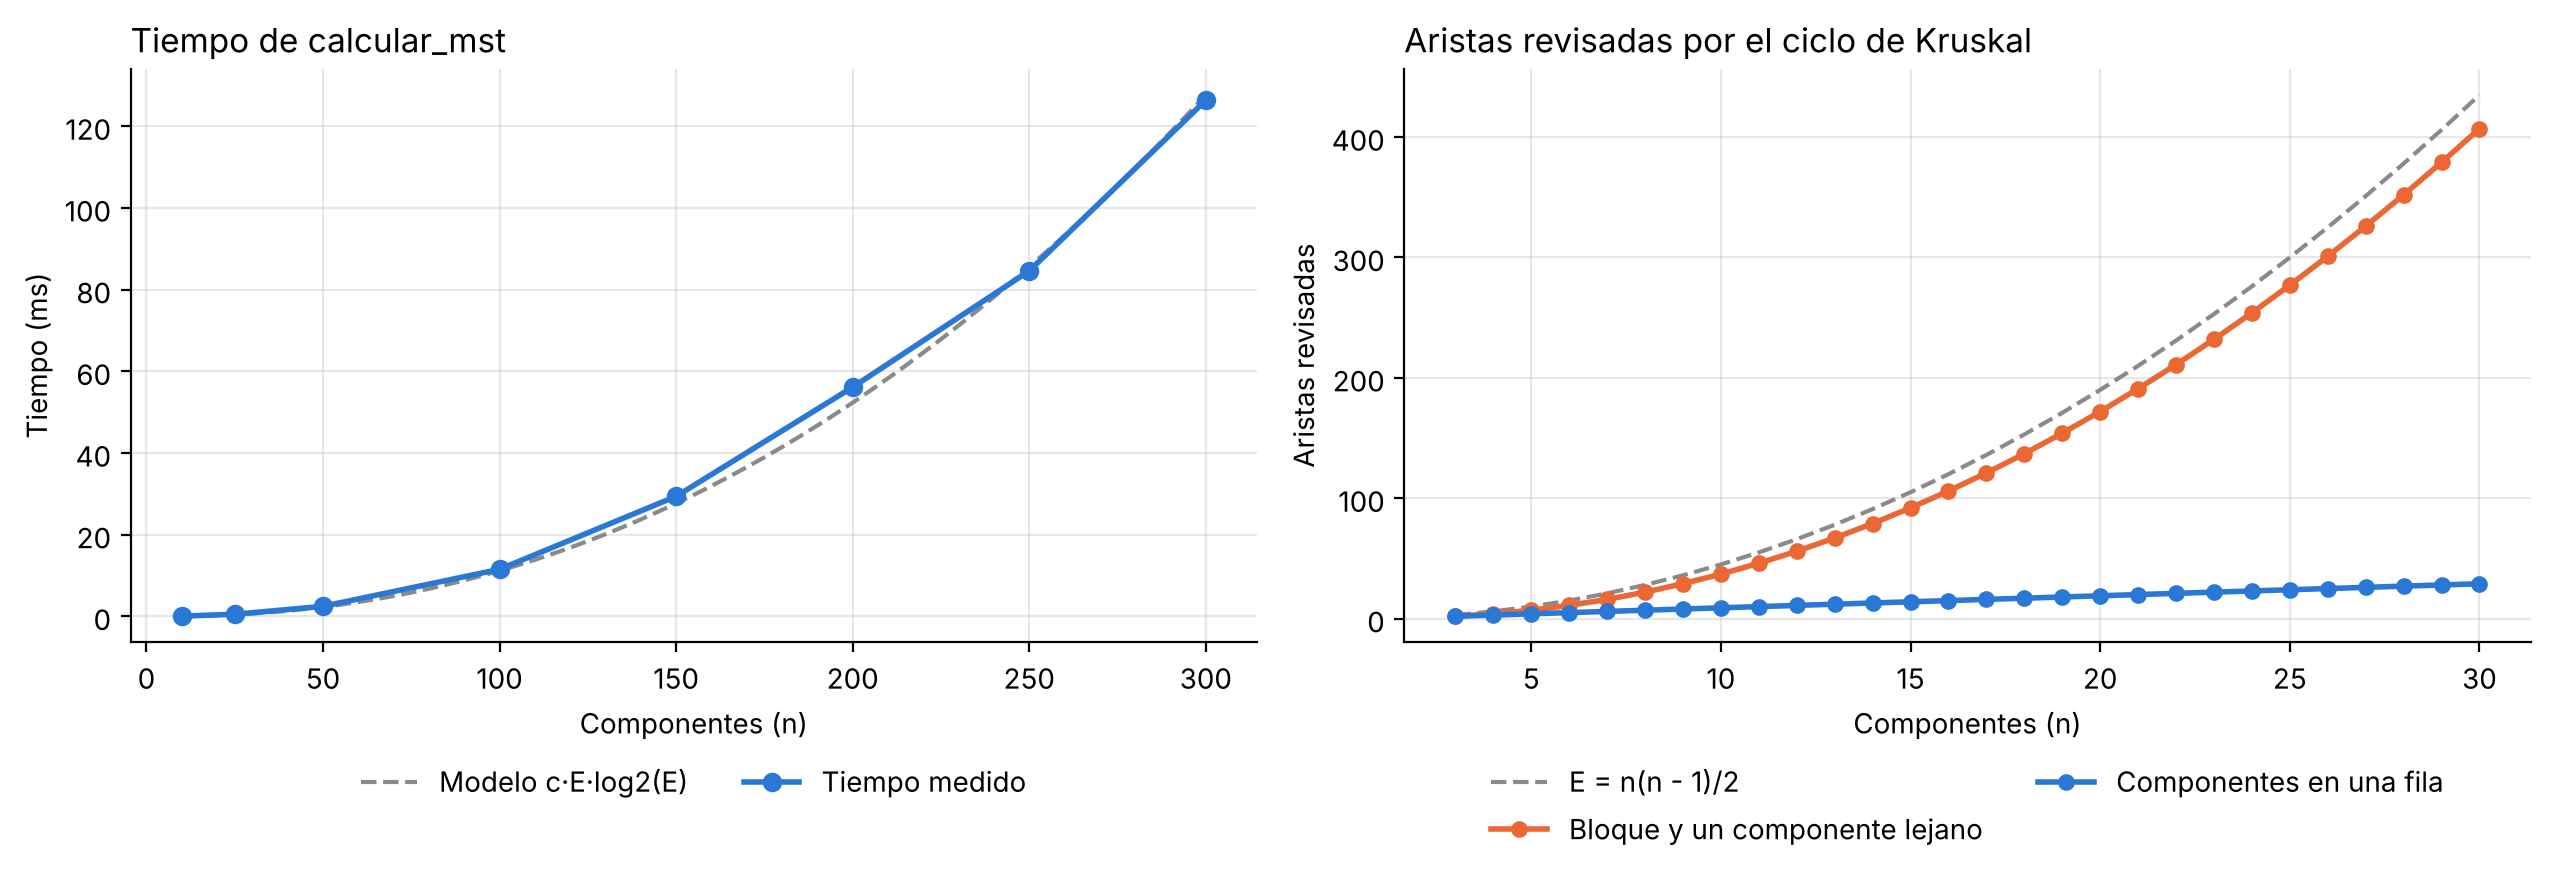

In [19]:
def tiempo_mst(posiciones, repeticiones=5):
    mejor = math.inf
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        calcular_mst(posiciones)
        mejor = min(mejor, time.perf_counter() - inicio)
    return mejor


def en_fila(n):
    return {f"C{c}": f"A{c}" for c in range(1, n + 1)}


def bloque_y_lejano(n):
    bloque = [f"{f}{c}" for f in "ABCDE" for c in range(1, 7)]
    posiciones = {f"C{i}": bloque[i] for i in range(n - 1)}
    posiciones["lejano"] = "J30"
    return posiciones


random.seed(7)
tamanos = [10, 25, 50, 100, 150, 200, 250, 300]
tiempos, cocientes = [], []
print(f"{'n':>5}{'E':>9}{'tiempo (ms)':>14}{'ns por E·log2(E)':>19}")
for n in tamanos:
    lugares = random.sample(huecos, n)
    t = tiempo_mst({f"C{i}": lugares[i] for i in range(n)})
    tiempos.append(t)
    E = n * (n - 1) // 2
    E_texto = f"{E:,}".replace(",", ".")
    cociente = t / (E * math.log2(E)) * 1e9
    if n >= 50:
        cocientes.append(cociente)
    print(f"{n:>5}{E_texto:>9}{t * 1e3:>14.2f}{cociente:>19.1f}")

crece = tiempos[tamanos.index(300)] / tiempos[tamanos.index(150)]
t_lab = tiempo_mst(POSICIONES, 200)
print(f"\nDesde n = 50 el cociente queda entre {min(cocientes):.1f} y {max(cocientes):.1f} ns.")
print(f"De n = 150 a n = 300 el tiempo se multiplicó por {crece:.2f}; n² log n predice 4.61 y n² daría 4.")
print(f"Caso del laboratorio (n = 7, E = 21): {t_lab * 1e6:.1f} µs\n")

ns = list(range(3, 31))
revisadas_mejor = [len(calcular_mst(en_fila(n))[2]) for n in ns]
revisadas_peor = [len(calcular_mst(bloque_y_lejano(n))[2]) for n in ns]
test("Mejor caso: Kruskal revisa exactamente n - 1 aristas", revisadas_mejor == [n - 1 for n in ns], True)
esperadas_peor = [(n - 1) * (n - 2) // 2 + 1 for n in ns]
test("Peor caso: revisa todas las aristas del bloque y una más", revisadas_peor == esperadas_peor, True)

g = [n * (n - 1) / 2 * math.log2(n * (n - 1) / 2) for n in tamanos]
c = sum(t * x for t, x in zip(tiempos, g)) / sum(x * x for x in g)
curva = list(range(10, 301, 5))
modelo = [c * n * (n - 1) / 2 * math.log2(n * (n - 1) / 2) * 1e3 for n in curva]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
ax1.plot(curva, modelo, color="#8a8a8a", lw=1.5, ls="--", label="Modelo c·E·log2(E)")
ax1.plot(tamanos, [t * 1e3 for t in tiempos], "o-", color="#2a78d6", lw=2, ms=6, label="Tiempo medido")
ax1.set_title("Tiempo de calcular_mst", loc="left")
ax1.set_xlabel("Componentes (n)")
ax1.set_ylabel("Tiempo (ms)")
ax2.plot(ns, [n * (n - 1) / 2 for n in ns], color="#8a8a8a", lw=1.5, ls="--", label="E = n(n - 1)/2")
ax2.plot(ns, revisadas_peor, "o-", color="#eb6834", lw=2, ms=5, label="Bloque y un componente lejano")
ax2.plot(ns, revisadas_mejor, "o-", color="#2a78d6", lw=2, ms=5, label="Componentes en una fila")
ax2.set_title("Aristas revisadas por el ciclo de Kruskal", loc="left")
ax2.set_xlabel("Componentes (n)")
ax2.set_ylabel("Aristas revisadas")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

### Interpretación

La última columna divide el tiempo entre $E \log_2 E$. Si el algoritmo es $\Theta(E \log E) = \Theta(n^2 \log n)$, ese cociente debe quedar casi constante aunque E se multiplique por 36 entre n = 50 y n = 300 (de 1.225 a 44.850 aristas), y eso es lo que muestra la tabla: el rango impreso debajo de ella varía poco. Con n = 10 el cociente es mayor porque pesa más el costo fijo de llamar las funciones. Al duplicar n de 150 a 300 el tiempo se multiplica por un valor cercano al 4,6 que predice $n^2 \log n$; un algoritmo solo cuadrático daría 4 y uno cúbico, 8. En la gráfica de la izquierda la curva medida sigue al modelo $c \cdot E \log_2 E$.

En la gráfica de la derecha, con los componentes en una fila Kruskal revisó exactamente n - 1 aristas (mejor caso), y con el bloque y el componente lejano revisó todas las aristas del bloque más una (peor caso), siguiendo la curva de E. Aun así, el tiempo total lo domina el ordenamiento, como se vio en el análisis de complejidad. Los tiempos exactos cambian en cada ejecución y en cada computador; lo que se mantiene es la forma de las curvas.

In [20]:
print(f"{len(resultados)} pruebas ejecutadas, {len(resultados)} superadas")

98 pruebas ejecutadas, 98 superadas


## Conclusiones

1. El problema se modela como un grafo completo de 7 vértices y 21 aristas con peso Manhattan, y el cableado mínimo es su árbol de expansión mínima: 6 cables y 45 unidades, frente a 103 si todo se conectara directo a la fuente.
2. Kruskal llegó al resultado revisando solo 8 de las 21 conexiones, y los conjuntos disjuntos detectaron los dos ciclos (B - R y F - B) sin recorrer el árbol.
3. Al mover el Buzzer a J20 el cable bajó de 45 a 42 unidades ($-6{,}7\,\%$), porque el Buzzer quedó entre el Potenciómetro y el Microcontrolador y reemplazó dos cables más largos.
4. El costo es $\Theta(n^2 \log n)$ y lo domina el ordenamiento de las aristas; las mediciones lo confirman, porque el tiempo dividido por $E \log_2 E$ se mantiene casi constante.
5. Las pruebas, entre ellas la fuerza bruta sobre los 16.807 árboles posibles, la comparación con Prim y la propiedad del ciclo, confirman que 45 y 42 son los mínimos y que en los dos casos el árbol es único.